# The Missing 1.54%
### A mund ta mësojmë një makinë të njohë një gjendje emocionale që në dataset pothuajse nuk ekziston?

**Studim eksperimental mbi SMOTE në sinjale fiziologjike: dataset-i BIOSTRESS**

Dataset-i [BIOSTRESS](https://data.mendeley.com/datasets/z9y2fn38fp/1) (Kocaçınar, Patlar Akbulut et al., Istanbul Kültür University, 2023; Mendeley Data, DOI: [10.17632/z9y2fn38fp.1](https://doi.org/10.17632/z9y2fn38fp.1)) përmban sinjale të regjistruara nga byzylyku **Empatica E4** gjatë një seance stresuese me psikolog dhe gjatë provimeve.

| Veçoria | Çfarë mat |
|---|---|
| `bvp` | Blood Volume Pulse: ndryshimet në vëllimin e gjakut |
| `eda` | Electrodermal Activity: djersitja e lëkurës (reagon fort ndaj stresit) |
| `hr` | Rrahjet e zemrës |
| `x, y, z` | Akselerometri: lëvizja e dorës |

Klasat janë **Normal** (gjendje e qetë), **Stressed** (stres nga detyra dhe presioni) dhe **Upset** (frustrim, irritim, shqetësim emocional).

**Plani i notebook-ut:**

| # | Rasti |
|---|---|
| 0 | Si funksionon SMOTE, hap pas hapi |
| 1 | Eksplorimi: sinjalet dhe zbulimi se nga vjen klasa Upset |
| 2 | **Rasti A:** ndarje rastësore, rezultat "i mrekullueshëm" |
| 2b | **SMOTE nën mikroskop:** 8 vizualizime të mekanizmit mbi të dhënat reale |
| 3 | **Rasti B:** pse rezultati i rastit A është iluzion |
| 4 | **Rasti C:** testi i ndershëm, një seancë që modeli s'e ka parë kurrë |
| 5 | **Rasti D:** ndarje kronologjike, një kompromis i arsyeshëm |
| 6 | **Rasti E:** SMOTE kundrejt Random Oversampling dhe class weights |
| 7 | **Sa të qëndrueshme janë rezultatet?** Përsëritje me ndarje të ndryshme |
| 8 | Kufizimet |
| 9 | Përfundimet |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (recall_score, precision_score, f1_score,
                             balanced_accuracy_score, ConfusionMatrixDisplay)

from smote import smote, k_fqinjet_me_te_afert

RS = 42
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
# Paletë e verifikuar për daltonizëm: Stressed = blu, Upset = portokalli, sintetike = gjelbër-uji
GRI, C_STRESS, C_UPSET, C_SINT, C_TEST = "#a3a29c", "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
NGJYRAT = {"Normal": GRI, "Stressed": C_STRESS, "Upset": C_UPSET}

---
## 0. Si funksionon SMOTE, hap pas hapi

Për një pikë **x** të pakicës:
1. gjejmë **k fqinjët** e saj më të afërt (po nga pakica),
2. zgjedhim një prej tyre rastësisht,
3. krijojmë një pikë të re në segmentin mes tyre: $x_{ri} = x + \lambda (x_{fqinj} - x)$, me $\lambda \sim U(0,1)$.

Implementimi i plotë ndodhet te [smote.py](smote.py).

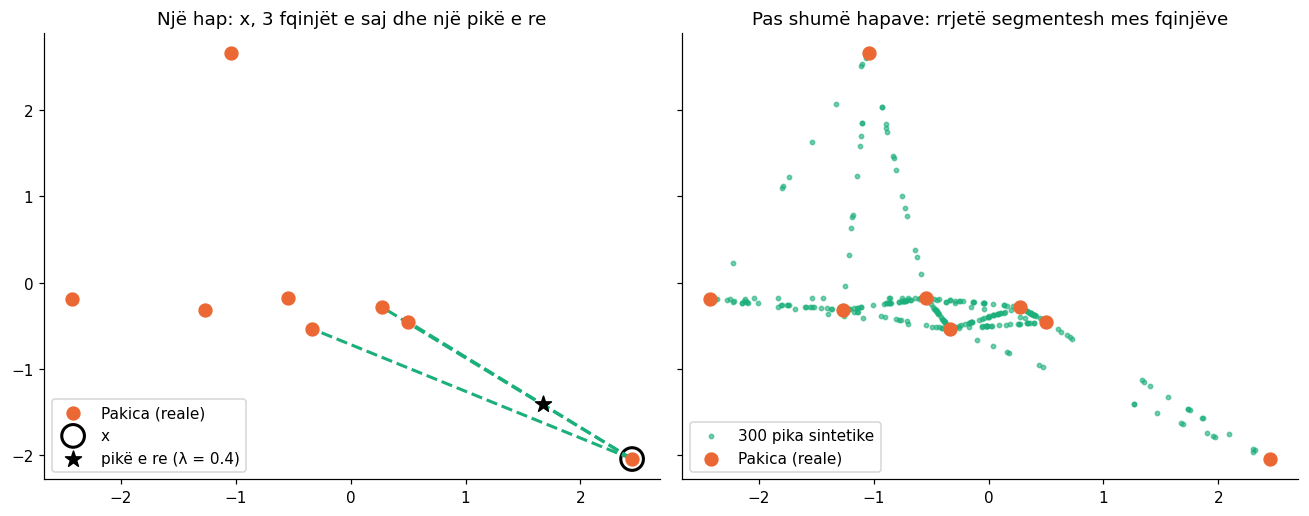

In [2]:
rng = np.random.default_rng(3)
P = rng.normal(size=(8, 2)) * [1.2, 0.8]               # 8 pika të pakicës
k = 3
fqinjet = k_fqinjet_me_te_afert(P, k)
x = 0                                                   # pika që po e shqyrtojmë
S = smote(P, 300, k=k, random_state=1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True, sharey=True)
ax[0].scatter(*P.T, s=70, c=C_UPSET, zorder=3, label="Pakica (reale)")
for j in fqinjet[x]:
    ax[0].plot(*np.c_[P[x], P[j]], c=C_SINT, lw=2, ls="--", zorder=2)
lam = 0.4; j = fqinjet[x][0]
x_ri = P[x] + lam * (P[j] - P[x])
ax[0].scatter(*P[x], s=220, facecolors="none", edgecolors="k", lw=2, label="x")
ax[0].scatter(*x_ri, s=120, marker="*", c="k", zorder=4, label=f"pikë e re (λ = {lam})")
ax[0].set_title(f"Një hap: x, {k} fqinjët e saj dhe një pikë e re")
ax[0].legend(loc="lower left")

ax[1].scatter(*S.T, s=8, c=C_SINT, alpha=0.6, label="300 pika sintetike")
ax[1].scatter(*P.T, s=70, c=C_UPSET, zorder=3, label="Pakica (reale)")
ax[1].set_title("Pas shumë hapave: rrjetë segmentesh mes fqinjëve")
ax[1].legend(loc="lower left")
plt.tight_layout(); plt.show()

**Çfarë duhet mbajtur mend nga ky grafik:** SMOTE **nuk shpik zona të reja**. Çdo pikë sintetike shtrihet në një segment mes dy pikave reale. Prandaj SMOTE mund ta "mbushë" zonën ku pakica tashmë ekziston, por nuk mund të krijojë diçka që nuk e ka parë kurrë. Kjo do të jetë thelbësore më poshtë.

---
## 1. Eksplorimi

Përdorim skedarin `downsample.csv`, ku sinjalet janë me **4 matje në sekondë** (një rresht = 0.25 s).

In [3]:
bio = pd.read_csv("data/biostress/downsample.csv")
EMRAT = {0: "Normal", 1: "Stressed", 2: "Upset"}
VECORI = ["bvp", "eda", "hr", "x", "y", "z"]

print(bio.shape, "| vlera që mungojnë:", bio.isna().sum().sum())
display(bio.head())
pd.DataFrame({"rreshta": bio.LABEL.value_counts().sort_index(),
              "%": (bio.LABEL.value_counts(normalize=True).sort_index() * 100).round(2),
              "minuta": (bio.LABEL.value_counts().sort_index() / 4 / 60).round(1)}
            ).rename(index=EMRAT)

(103812, 8) | vlera që mungojnë: 0


,time(s),bvp,eda,hr,x,y,z,LABEL
0,10.00,-19.96,1.553661,52.0,25.375,4.750,59.250,0
1,10.25,-29.30,1.581831,52.0,25.500,5.000,58.625,0
2,10.50,-10.06,1.622807,52.0,24.125,3.875,59.500,0
3,10.75,-5.77,1.656099,52.0,28.000,0.250,61.875,0
4,11.00,37.60,1.680428,52.0,41.875,28.500,34.375,0


,rreshta,%,minuta
LABEL,,,
Normal,55569,53.53,231.5
Stressed,46646,44.93,194.4
Upset,1597,1.54,6.7


### 1.1 Si duken sinjalet sipas klasës?

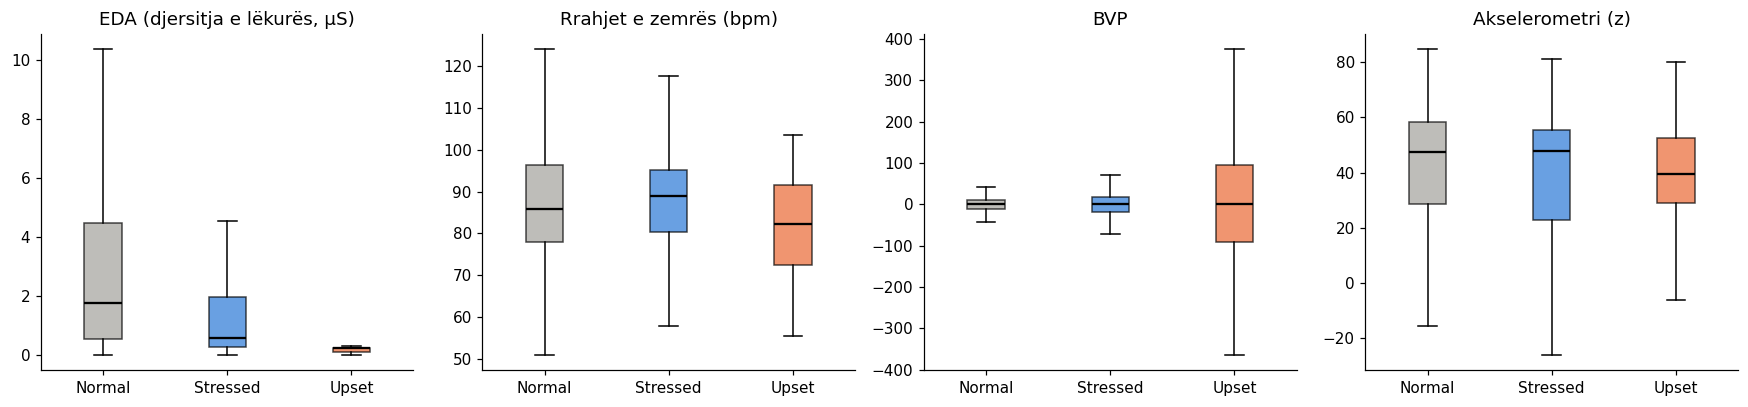

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for a, kol, titulli in zip(axes, ["eda", "hr", "bvp", "z"],
                           ["EDA (djersitja e lëkurës, μS)", "Rrahjet e zemrës (bpm)", "BVP", "Akselerometri (z)"]):
    te_dhenat = [bio.loc[bio.LABEL == c, kol] for c in [0, 1, 2]]
    bp = a.boxplot(te_dhenat, tick_labels=list(EMRAT.values()), showfliers=False, patch_artist=True,
                   medianprops=dict(color="black", lw=1.5))
    for kuti, ngj in zip(bp["boxes"], NGJYRAT.values()):
        kuti.set_facecolor(ngj); kuti.set_alpha(0.7)
    a.set_title(titulli)
plt.tight_layout(); plt.show()

Në pamje të parë, Upset duket shumë i veçantë: EDA shumë e ulët dhe BVP që luhatet shumë. **Por kujdes:** siç do ta shohim menjëherë, këto dallime mund ta pasqyrojnë kryesisht **një person të vetëm**, jo vetë emocionin.

### 1.2 Zbulimi: kush janë "1.54%"?

Dataset-i **nuk ka kolonë për pjesëmarrësin**. Por kolona `time(s)` rritet me 0.25 s dhe **rifillon nga ~10 s** sa herë fillon një regjistrim i ri. Nga këto rifillime mund t'i rindërtojmë **seancat** e regjistrimit.

In [5]:
t = bio["time(s)"].to_numpy()
bio["seanca"] = np.concatenate([[0], np.cumsum(np.diff(t) < 0)])

seancat = (bio.groupby(["seanca", "LABEL"]).size().unstack(fill_value=0)
              .rename(columns=EMRAT))
seancat["minuta"] = (bio.groupby("seanca").size() / 4 / 60).round(1)
print("Numri i seancave:", bio.seanca.nunique())
seancat.T

Numri i seancave: 24


seanca,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
LABEL,,,,,,,,,,,,,,,,,,,,,
Normal,3217.0,1386.0,1311.0,1805.0,1530.0,2504.0,1235.0,1436.0,1553.0,1050.0,...,2578.0,1183.0,1056.0,2584.0,2067.0,2019.0,7162.0,8586.0,271.0,3268.0
Stressed,484.0,319.0,382.0,168.0,404.0,546.0,272.0,228.0,1707.0,1982.0,...,815.0,1170.0,52.0,281.0,264.0,111.0,4965.0,4207.0,10318.0,13937.0
Upset,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1541.0,0.0,53.0,3.0,0.0,0.0,0.0,0.0
minuta,15.4,7.1,7.1,8.2,8.1,12.7,6.3,6.9,13.6,12.6,...,14.1,9.8,11.0,11.9,9.9,8.9,50.5,53.3,44.1,71.7


seanca
16    1541
18      53
19       3

Seanca 16 përmban 96.5% të të gjitha rreshtave 'Upset'.


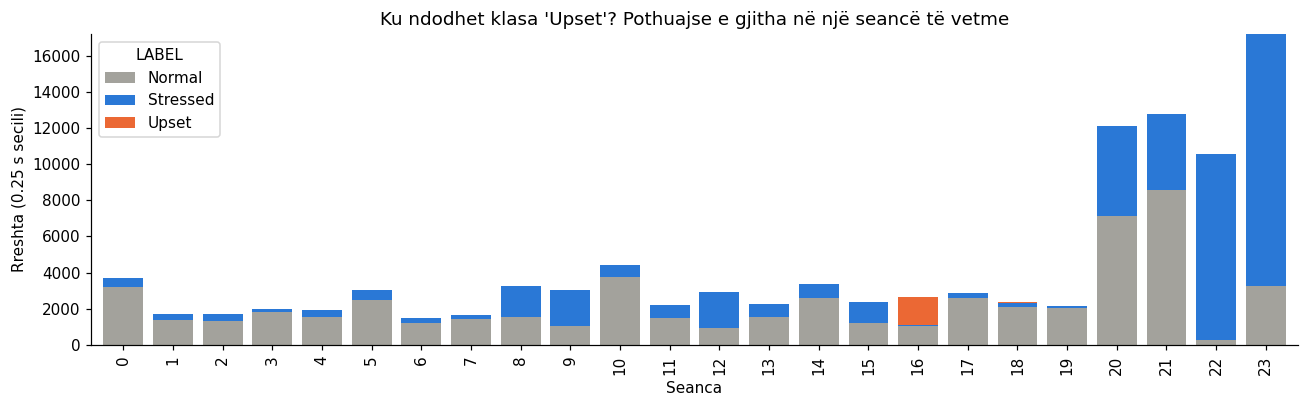

In [6]:
upset_sipas_seances = bio[bio.LABEL == 2].seanca.value_counts()
print(upset_sipas_seances.to_string())
print(f"\nSeanca {upset_sipas_seances.index[0]} përmban "
      f"{upset_sipas_seances.iloc[0] / upset_sipas_seances.sum():.1%} të të gjitha rreshtave 'Upset'.")

fig, ax = plt.subplots(figsize=(12, 3.8))
seancat[list(NGJYRAT)].plot.bar(stacked=True, ax=ax, color=list(NGJYRAT.values()), width=0.8)
ax.set_xlabel("Seanca"); ax.set_ylabel("Rreshta (0.25 s secili)")
ax.set_title("Ku ndodhet klasa 'Upset'? Pothuajse e gjitha në një seancë të vetme")
plt.tight_layout(); plt.show()

> **Zbulimi:** "1.54%" nuk janë shumë njerëz të ndryshëm të mërzitur. **~96.5% e klasës Upset vjen nga një seancë e vetme** (seanca 16, rreth 6.4 minuta). Pjesa tjetër është 53 rreshta nga seanca 18 dhe 3 nga seanca 19.
>
> Pra, pyetja reale nuk është *"a e njeh modeli mërzinë?"*. Pyetja është *"a e njeh modeli këtë person në këto 6 minuta?"*. Le ta shohim si ndikon kjo te SMOTE.

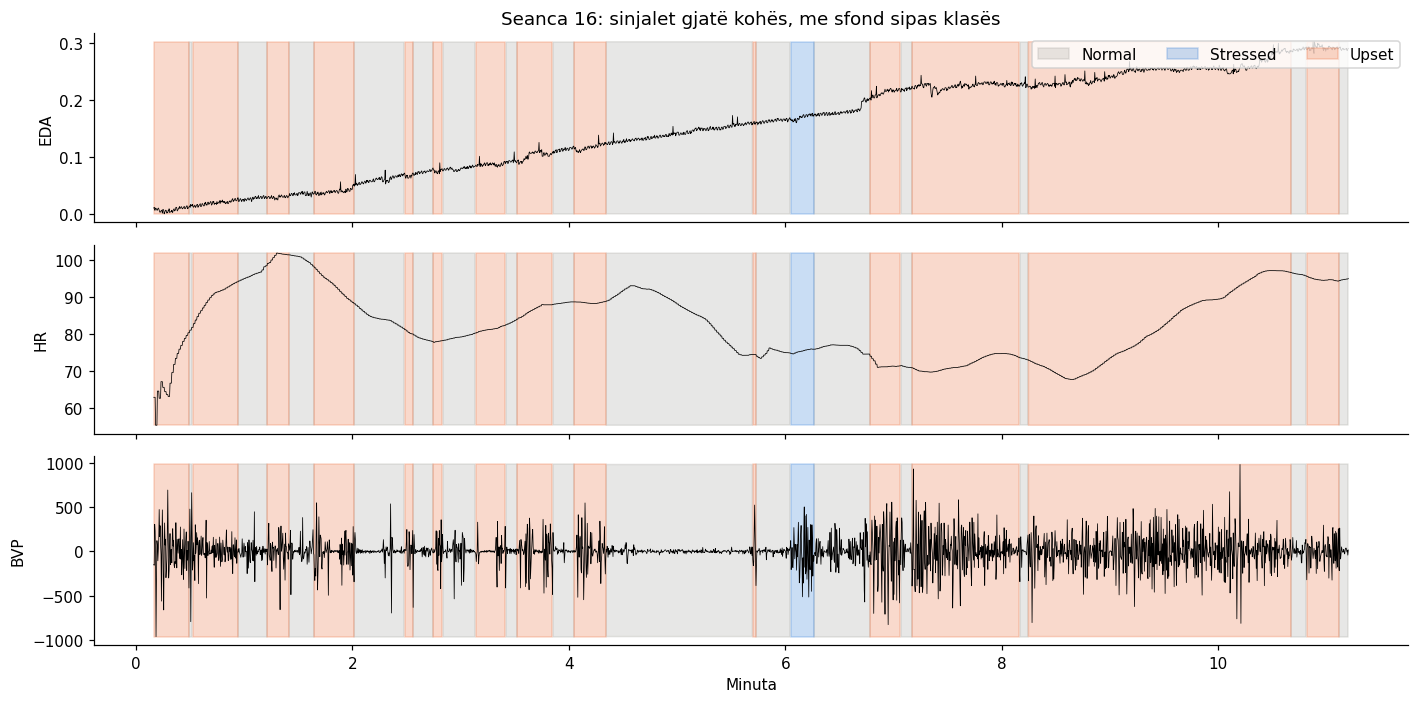

In [7]:
s16 = bio[bio.seanca == 16]
fig, axes = plt.subplots(3, 1, figsize=(13, 6.5), sharex=True)
for a, kol in zip(axes, ["eda", "hr", "bvp"]):
    a.plot(s16["time(s)"] / 60, s16[kol], c="k", lw=0.5)
    for c, ngj in zip([0, 1, 2], NGJYRAT.values()):
        m = (s16.LABEL == c).to_numpy()
        a.fill_between(s16["time(s)"] / 60, s16[kol].min(), s16[kol].max(), where=m,
                       color=ngj, alpha=0.25, step="mid", label=EMRAT[c] if kol == "eda" else None)
    a.set_ylabel(kol.upper())
axes[0].set_title("Seanca 16: sinjalet gjatë kohës, me sfond sipas klasës")
axes[0].legend(loc="upper right", ncol=3)
axes[-1].set_xlabel("Minuta")
plt.tight_layout(); plt.show()

Dy vëzhgime nga ky grafik:
- **Upset shfaqet në episode**, që alternohen me periudha Normal brenda së njëjtës seancë. Rreshtat e një episodi janë vazhdim i njëri-tjetrit, pra shumë të ngjashëm mes tyre.
- Gjatë episodeve Upset, **BVP luhatet shumë më fort**. Kjo mund të vijë nga emocioni, por edhe nga lëvizja e dorës (p.sh. kur personi flet ose bën gjeste). Me të dhëna nga një person i vetëm, nuk mund t'i dallojmë këto dy shkaqe.

Të dyja këto do të kenë rëndësi të madhe kur ta ndajmë dataset-in në train dhe test.

---
## Mjetet e eksperimentit

Përdorim gjithmonë të njëjtin model (**Random Forest**) dhe ndryshojmë vetëm dy gjëra:
- **si e ndajmë** train / test (`maska_test`),
- **çfarë strategjie** përdorim për klasën Upset:

| Strategjia | Ideja |
|---|---|
| `asgje` | Modeli bazë |
| `smote` | Krijon rreshta Upset sintetikë mes fqinjëve (implementimi ynë) |
| `ros` | Random Oversampling: kopjon rreshtat Upset ekzistues |
| `cw` | `class_weight="balanced"`: nuk shton të dhëna, por e "dënon" më shumë modelin kur gabon te pakica |

Te `smote` dhe `ros`, klasa Upset në train ngrihet deri sa të barazohet me klasën Stressed. Standardizimi dhe SMOTE bëhen **vetëm me të dhënat e train**.

In [8]:
def eksperiment(maska_test, strategjia="asgje", k=5):
    Xtr, ytr = bio.loc[~maska_test, VECORI].to_numpy(), bio.loc[~maska_test, "LABEL"].to_numpy()
    Xte, yte = bio.loc[maska_test, VECORI].to_numpy(), bio.loc[maska_test, "LABEL"].to_numpy()

    sc = StandardScaler().fit(Xtr)                       # fit vetëm në train
    Xtr, Xte = sc.transform(Xtr), sc.transform(Xte)
    ytr_para = ytr.copy()

    n_te_reja = (ytr == 1).sum() - (ytr == 2).sum()
    X_shtese = np.empty((0, Xtr.shape[1]))
    if strategjia == "smote":
        X_shtese = smote(Xtr[ytr == 2], n_te_reja, k=k, random_state=RS)
    elif strategjia == "ros":
        rng = np.random.default_rng(RS)
        X_shtese = Xtr[ytr == 2][rng.integers(0, (ytr == 2).sum(), n_te_reja)]
    if len(X_shtese):
        Xtr = np.vstack([Xtr, X_shtese]); ytr = np.concatenate([ytr, np.full(len(X_shtese), 2)])

    model = RandomForestClassifier(n_estimators=150, min_samples_leaf=2, n_jobs=-1, random_state=RS,
                                   class_weight="balanced" if strategjia == "cw" else None)
    y_pred = model.fit(Xtr, ytr).predict(Xte)
    return dict(yte=yte, y_pred=y_pred, ytr_para=ytr_para, ytr_pas=ytr, X_shtese=X_shtese, scaler=sc)

def metrikat(r, rasti, strategjia):
    yte, p = r["yte"], r["y_pred"]
    return {"Rasti": rasti, "Strategjia": strategjia,
            "Upset në test": int((yte == 2).sum()),
            "Recall (Upset)": recall_score(yte, p, labels=[2], average="macro", zero_division=0),
            "Precision (Upset)": precision_score(yte, p, labels=[2], average="macro", zero_division=0),
            "Macro F1": f1_score(yte, p, average="macro"),
            "Balanced Acc.": balanced_accuracy_score(yte, p)}

def matricat(r_pa, r_me, titulli):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
    for a, r, t in [(ax[0], r_pa, "Pa SMOTE"), (ax[1], r_me, "Me SMOTE")]:
        ConfusionMatrixDisplay.from_predictions(r["yte"], r["y_pred"], display_labels=list(EMRAT.values()),
                                                ax=a, cmap="Oranges", colorbar=False)
        a.set_title(f"{titulli}: {t}")
    plt.tight_layout(); plt.show()

rezultatet = []

---
## 2. Rasti A: ndarja e rastësishme e rreshtave, rezultat "i mrekullueshëm"

Kjo është ajo që bën shumica e tutorialëve: `train_test_split` mbi rreshtat, pastaj SMOTE vetëm në train. Procedura duket "korrekte".

In [9]:
idx_train, idx_test = train_test_split(bio.index, test_size=0.3, stratify=bio.LABEL, random_state=RS)
maska_A = bio.index.isin(idx_test)

rA_pa = eksperiment(maska_A, "asgje")
rA_me = eksperiment(maska_A, "smote")
rezultatet += [metrikat(rA_pa, "A) Rastësore", "Pa SMOTE"), metrikat(rA_me, "A) Rastësore", "SMOTE")]
pd.DataFrame(rezultatet).round(3)

,Rasti,Strategjia,Upset në test,Recall (Upset),Precision (Upset),Macro F1,Balanced Acc.
0,A) Rastësore,Pa SMOTE,479,0.827,0.966,0.939,0.918
1,A) Rastësore,SMOTE,479,0.946,0.802,0.931,0.956


### Shpërndarja e klasave në train, para dhe pas SMOTE

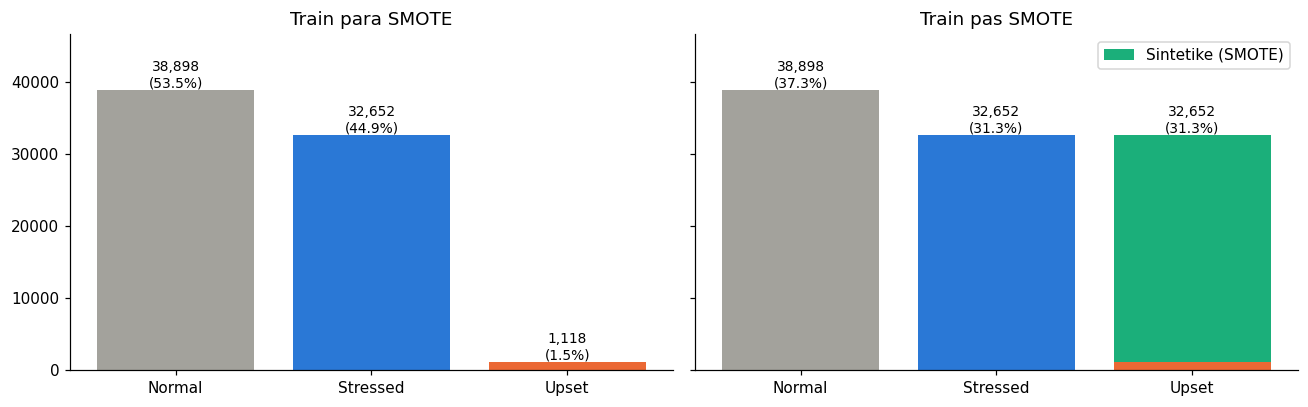

Nga 1,118 rreshta reale Upset, SMOTE krijoi 31,534 sintetike (~28 për çdo rresht real).


In [10]:
para = pd.Series(rA_me["ytr_para"]).value_counts().sort_index().rename(EMRAT)
pas = pd.Series(rA_me["ytr_pas"]).value_counts().sort_index().rename(EMRAT)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for a, v, t in [(ax[0], para, "Train para SMOTE"), (ax[1], pas, "Train pas SMOTE")]:
    b = a.bar(v.index, v.values, color=[NGJYRAT[i] for i in v.index])
    a.bar_label(b, labels=[f"{n:,}\n({n / v.sum():.1%})" for n in v.values], fontsize=9)
    a.set_title(t)
ax[1].bar(["Upset"], [len(rA_me["X_shtese"])], bottom=[para["Upset"]], color=C_SINT, label="Sintetike (SMOTE)")
ax[1].legend(loc="upper right")
ax[0].set_ylim(0, pas.max() * 1.2)
plt.tight_layout(); plt.show()
print(f"Nga {para['Upset']:,} rreshta reale Upset, SMOTE krijoi {len(rA_me['X_shtese']):,} sintetike "
      f"(~{len(rA_me['X_shtese']) / para['Upset']:.0f} për çdo rresht real).")

### PCA: ku vendosen pikat sintetike?

PCA shpjegon 41% të variancës.


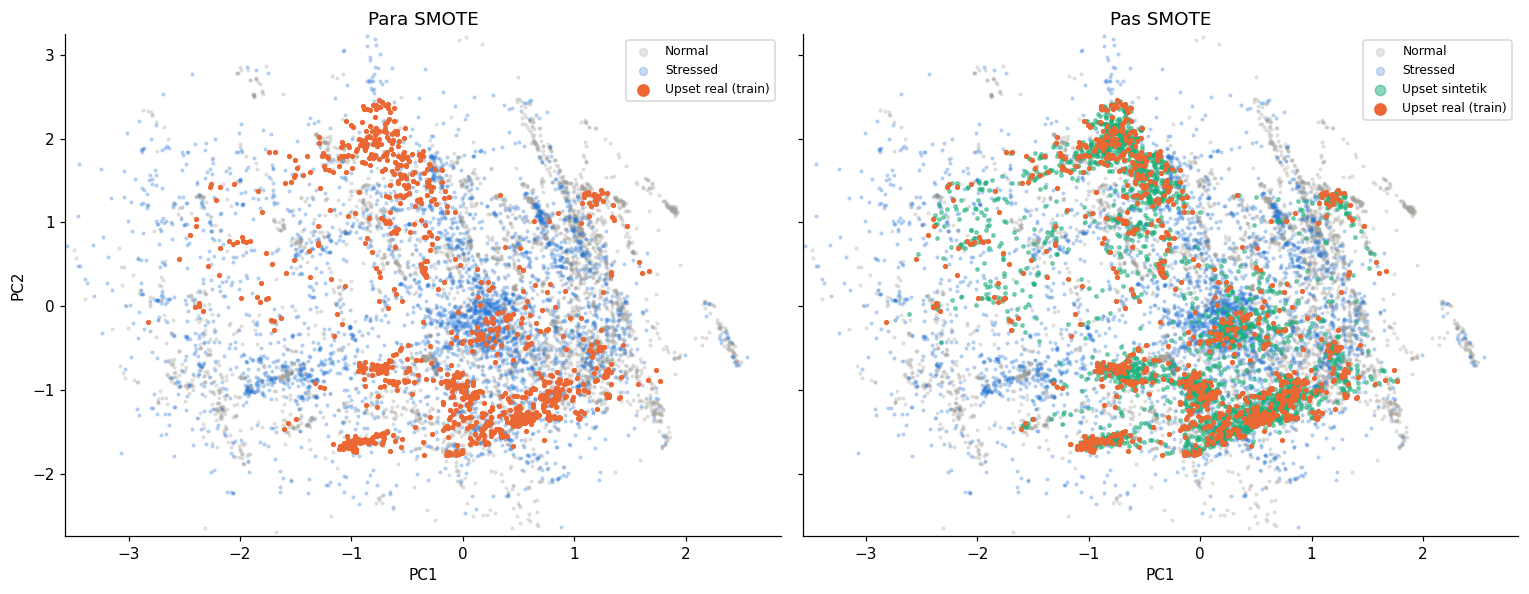

In [11]:
sc = rA_me["scaler"]
X_all = sc.transform(bio[VECORI].to_numpy())
pca = PCA(n_components=2).fit(X_all)
print(f"PCA shpjegon {pca.explained_variance_ratio_.sum():.0%} të variancës.")

sfond = bio.sample(8000, random_state=RS).index
P_sfond = pca.transform(X_all[sfond]); y_sfond = bio.loc[sfond, "LABEL"].to_numpy()
P_upset = pca.transform(X_all[((bio.LABEL == 2).to_numpy()) & ~maska_A])
P_sint = pca.transform(rA_me["X_shtese"][:4000])

lim_x = np.percentile(P_sfond[:, 0], [0.5, 99.5]); lim_y = np.percentile(P_sfond[:, 1], [0.5, 99.5])
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for a, me_sint, t in [(ax[0], False, "Para SMOTE"), (ax[1], True, "Pas SMOTE")]:
    for c in [0, 1]:
        a.scatter(*P_sfond[y_sfond == c].T, s=3, alpha=0.25, c=list(NGJYRAT.values())[c], label=EMRAT[c])
    if me_sint:
        a.scatter(*P_sint.T, s=5, c=C_SINT, alpha=0.5, label="Upset sintetik")
    a.scatter(*P_upset.T, s=6, c=C_UPSET, label="Upset real (train)")
    a.set_xlim(lim_x * 1.2); a.set_ylim(lim_y * 1.2); a.set_title(t)
    a.set_xlabel("PC1"); a.legend(loc="upper right", markerscale=3, fontsize=8)
ax[0].set_ylabel("PC2")
plt.tight_layout(); plt.show()

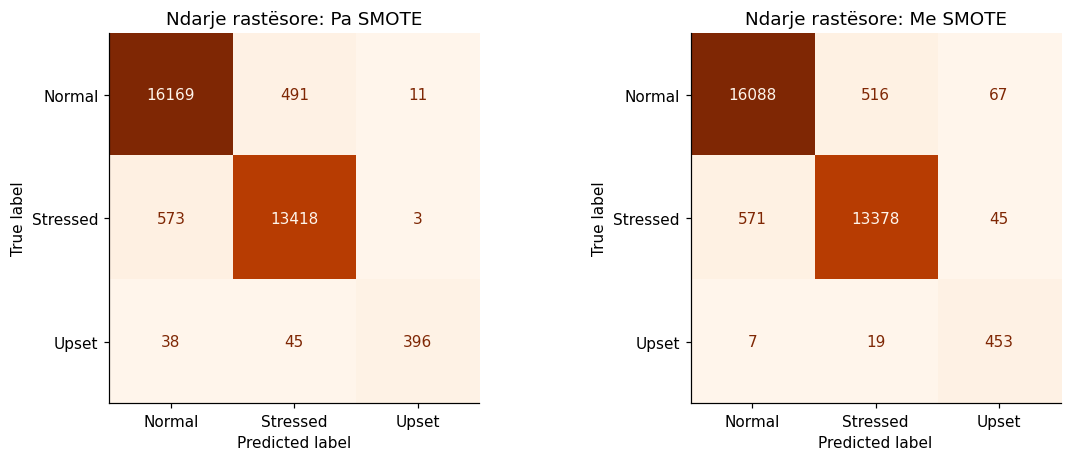

In [12]:
matricat(rA_pa, rA_me, "Ndarje rastësore")

Duket si sukses: SMOTE e ngre recall-in e Upset nga ~0.83 në ~0.95, ndërsa Macro F1 dhe Balanced Accuracy janë mbi 0.9. **Por a është i vërtetë ky rezultat?**

---
## 2b. SMOTE nën mikroskop

Deri tani e kemi parë SMOTE vetëm nga rezultatet e modelit. Këtu shohim **çfarë u bën SMOTE vetë të dhënave**. Përdorim rreshtat Upset të train-it nga Rasti A.

| # | Pyetja |
|---|---|
| M1 | Si duket nga afër një pikë sintetike e vetme? |
| M2 | Si duket "rrjeta" e segmenteve mbi sinjalet reale (EDA × HR)? |
| M3 | Si mbushet hapësira kur shtojmë gjithnjë e më shumë pika? |
| M4 | Kush janë fqinjët që përdor SMOTE, kur i shohim në kohë? |
| M5 | A kanë pikat sintetike të njëjtën shpërndarje si ato reale? |
| M6 | A ruhen lidhjet (korrelacionet) mes sinjaleve? |
| M7 | Sa pika sintetike bien në "territorin" e klasave të tjera? |
| M8 | Si e ndryshon SMOTE kufirin e vendimit të modelit? |

In [13]:
trA = bio.loc[~maska_A]
sc6 = StandardScaler().fit(trA[VECORI])
U_df = trA[trA.LABEL == 2]                       # Upset reale në train
U = sc6.transform(U_df[VECORI])                  # të standardizuara (SMOTE punon këtu)
K = 5
fq = k_fqinjet_me_te_afert(U, K)

S6 = smote(U, 30000, k=K, random_state=RS)       # 30 000 Upset sintetike
S6_orig = pd.DataFrame(sc6.inverse_transform(S6), columns=VECORI)   # kthyer në njësitë origjinale
print(f"Upset reale në train: {len(U):,} | sintetike: {len(S6):,}")

Upset reale në train: 1,118 | sintetike: 30,000


### M1. Anatomia e një pike sintetike

Marrim një rresht real Upset **x**, një nga fqinjët e tij dhe λ = 0.35. Pika e re ndodhet **në 35% të rrugës** nga x drejt fqinjit, dhe kjo vlen **njëkohësisht për çdo veçori**.

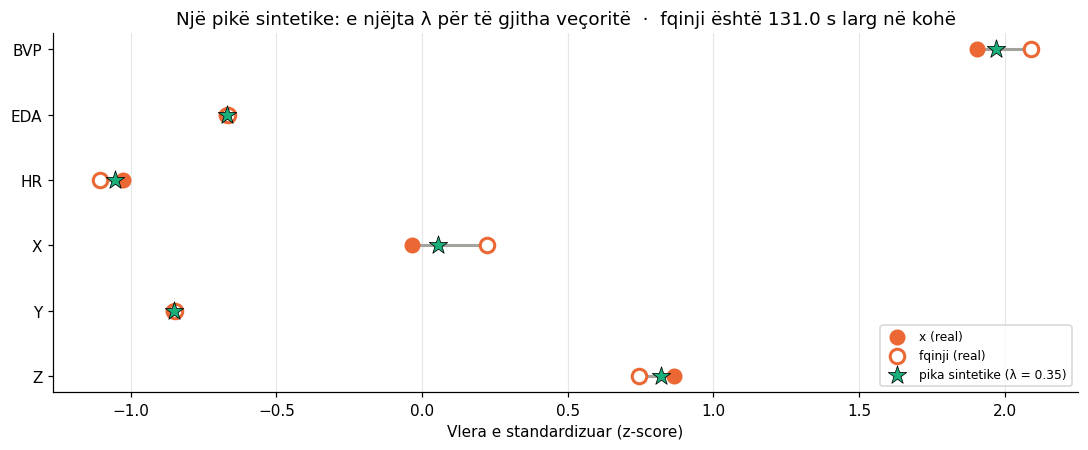

,x (real),fqinji (real),sintetike
bvp,142.700,156.650,147.582
eda,0.216,0.237,0.224
hr,74.030,72.950,73.652
x,15.000,24.375,18.281
y,-20.125,-20.000,-20.081
z,59.750,56.875,58.744


In [14]:
i = 400; j = fq[i, 2]; lam = 0.35
x_ri = U[i] + lam * (U[j] - U[i])

fig, ax = plt.subplots(figsize=(10, 4.2))
for f, emri in enumerate(VECORI):
    ax.plot([U[i, f], U[j, f]], [f, f], c=GRI, lw=2, zorder=1)
    ax.scatter(U[i, f], f, s=90, c=C_UPSET, zorder=3, label="x (real)" if f == 0 else None)
    ax.scatter(U[j, f], f, s=90, facecolors="white", edgecolors=C_UPSET, lw=2, zorder=3,
               label="fqinji (real)" if f == 0 else None)
    ax.scatter(x_ri[f], f, s=160, marker="*", c=C_SINT, edgecolors="k", lw=0.5, zorder=4,
               label=f"pika sintetike (λ = {lam})" if f == 0 else None)
ax.set_yticks(range(len(VECORI)), [v.upper() for v in VECORI]); ax.invert_yaxis()
ax.set_xlabel("Vlera e standardizuar (z-score)")
dt_ij = abs(U_df["time(s)"].iloc[i] - U_df["time(s)"].iloc[j])
ax.set_title(f"Një pikë sintetike: e njëjta λ për të gjitha veçoritë  ·  fqinji është {dt_ij:.1f} s larg në kohë")
ax.legend(loc="lower right", fontsize=8); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

pd.DataFrame({"x (real)": U_df[VECORI].iloc[i].to_numpy(),
              "fqinji (real)": U_df[VECORI].iloc[j].to_numpy(),
              "sintetike": sc6.inverse_transform(x_ri[None])[0]}, index=VECORI).round(3)

### M2. Rrjeta e SMOTE mbi sinjalet reale

Për ta parë me sy, e aplikojmë SMOTE vetëm në dy veçori: **EDA** (djersitja) dhe **HR** (rrahjet e zemrës). Çdo vijë lidh një rresht Upset me një nga 5 fqinjët e tij. Të gjitha pikat sintetike do të bien mbi këto vija.

EDA ndryshon shumë nga një person te tjetri (seanca 16 ka ~0–0.3 μS, seanca 18 rreth 5.5 μS). Prandaj për M2, M3 dhe M8 përdorim një "zoom" te **EDA ≤ 0.4 μS**, ku ndodhen ~97% e rreshtave Upset të train-it.

Në dritare: 20,156 rreshta train, nga të cilët 1,085 Upset (97% e Upset-it të train)


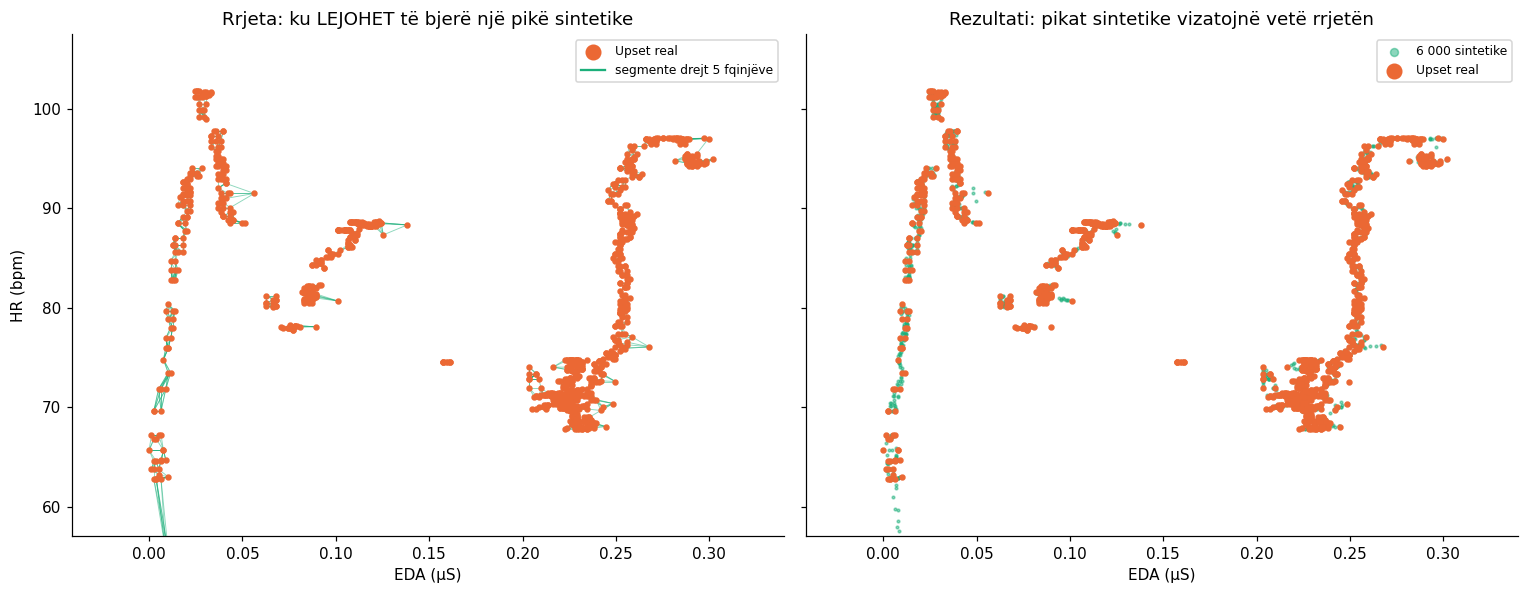

In [15]:
from matplotlib.collections import LineCollection

D2 = ["eda", "hr"]
W = trA[trA.eda <= 0.4]                          # dritarja e zmadhuar
U_df2 = W[W.LABEL == 2]
print(f"Në dritare: {len(W):,} rreshta train, nga të cilët {len(U_df2):,} Upset "
      f"({len(U_df2) / len(U_df):.0%} e Upset-it të train)")
sc2 = StandardScaler().fit(W[D2])
U2 = sc2.transform(U_df2[D2]); U2_orig = U_df2[D2].to_numpy()
fq2 = k_fqinjet_me_te_afert(U2, K)

segmentet = np.stack([np.repeat(U2_orig, K, axis=0), U2_orig[fq2.ravel()]], axis=1)
lim_x = np.percentile(U2_orig[:, 0], [0.5, 99.5]); lim_y = np.percentile(U2_orig[:, 1], [0.5, 99.5])
pad_x, pad_y = np.diff(lim_x)[0] * 0.15, np.diff(lim_y)[0] * 0.15
LIM_X, LIM_Y = (lim_x[0] - pad_x, lim_x[1] + pad_x), (lim_y[0] - pad_y, lim_y[1] + pad_y)

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
ax[0].add_collection(LineCollection(segmentet, colors=C_SINT, linewidths=0.6, alpha=0.5))
ax[0].scatter(*U2_orig.T, s=10, c=C_UPSET, zorder=3, label="Upset real")
ax[0].plot([], [], c=C_SINT, label=f"segmente drejt {K} fqinjëve")
ax[0].set_title("Rrjeta: ku LEJOHET të bjerë një pikë sintetike")

S2 = sc2.inverse_transform(smote(U2, 6000, k=K, random_state=RS))
ax[1].scatter(*S2.T, s=3, c=C_SINT, alpha=0.5, label="6 000 sintetike")
ax[1].scatter(*U2_orig.T, s=10, c=C_UPSET, zorder=3, label="Upset real")
ax[1].set_title("Rezultati: pikat sintetike vizatojnë vetë rrjetën")
for a in ax:
    a.set_xlim(LIM_X); a.set_ylim(LIM_Y); a.set_xlabel("EDA (μS)")
    a.legend(loc="upper right", markerscale=3, fontsize=8)
ax[0].set_ylabel("HR (bpm)")
plt.tight_layout(); plt.show()

Rreshtat Upset nuk formojnë një "re" pikash. Formojnë **trajektore**: momente të njëpasnjëshme të një sinjali që ndryshon ngadalë. Për shembull, EDA mbetet pothuajse konstante ndërsa HR rritet ose bie, dhe kjo jep vijat vertikale. SMOTE mbush hapësirat **përgjatë këtyre trajektoreve** dhe vetëm rrallë kalon mes tyre.

### M3. Si mbushet hapësira hap pas hapi

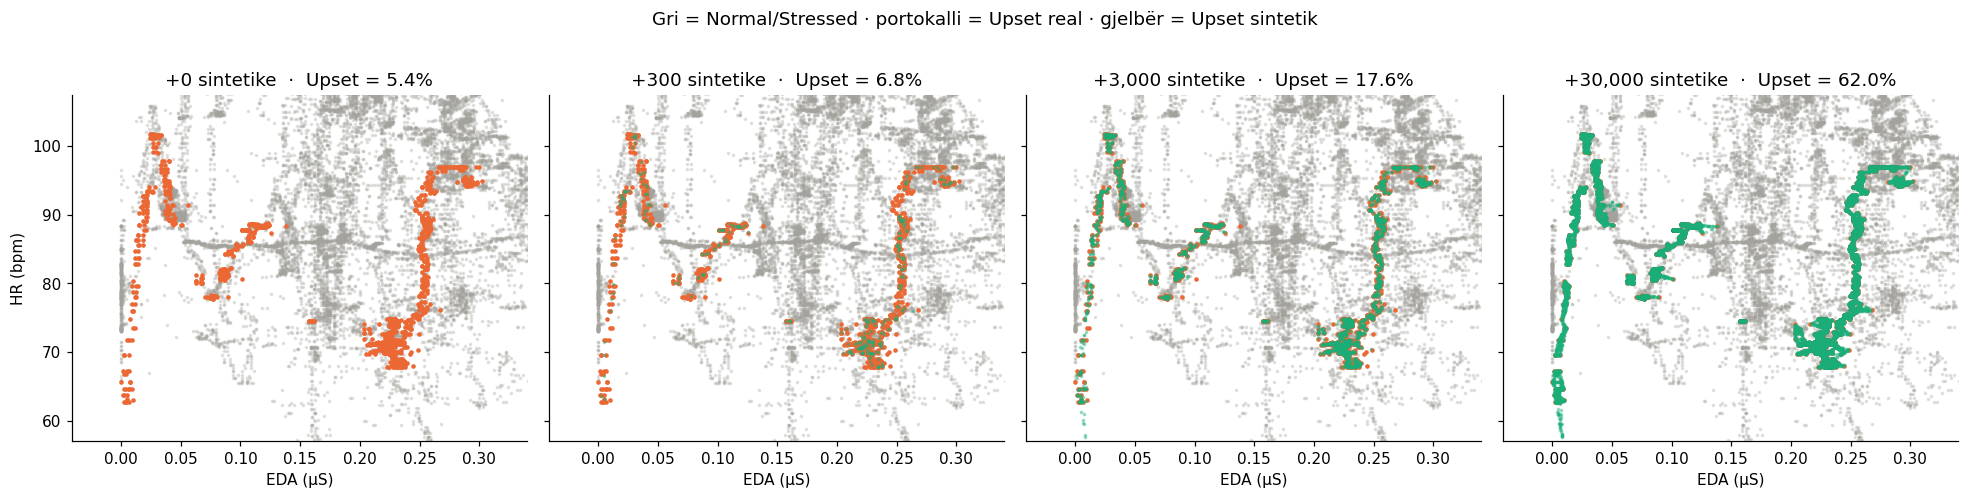

In [16]:
sfond2 = W[W.LABEL != 2].sample(15000, random_state=RS)
nn_list = [0, 300, 3000, 30000]
S2_plot = sc2.inverse_transform(smote(U2, max(nn_list), k=K, random_state=RS))

fig, axes = plt.subplots(1, 4, figsize=(18, 4.4), sharex=True, sharey=True)
for a, n in zip(axes, nn_list):
    a.scatter(sfond2.eda, sfond2.hr, s=2, c=GRI, alpha=0.25)
    a.scatter(*U2_orig.T, s=4, c=C_UPSET)
    if n:
        a.scatter(*S2_plot[:n].T, s=2, c=C_SINT, alpha=0.35)
    a.set_title(f"+{n:,} sintetike  ·  Upset = {(len(U2) + n) / (len(W) + n):.1%}")
    a.set_xlim(LIM_X); a.set_ylim(LIM_Y); a.set_xlabel("EDA (μS)")
axes[0].set_ylabel("HR (bpm)")
fig.suptitle("Gri = Normal/Stressed · portokalli = Upset real · gjelbër = Upset sintetik", y=1.02)
plt.tight_layout(); plt.show()

### M4. Kush janë fqinjët e SMOTE, kur i shohim në kohë?

SMOTE nuk e di që të dhënat janë seri kohore. Megjithatë, le ta shohim: sa larg në kohë janë fqinjët që zgjedh?

Fqinjë nga e njëjta seancë: 99.6%
Mediana e distancës në kohë: 15.8 s  |  ≤ 1 s: 10.7%


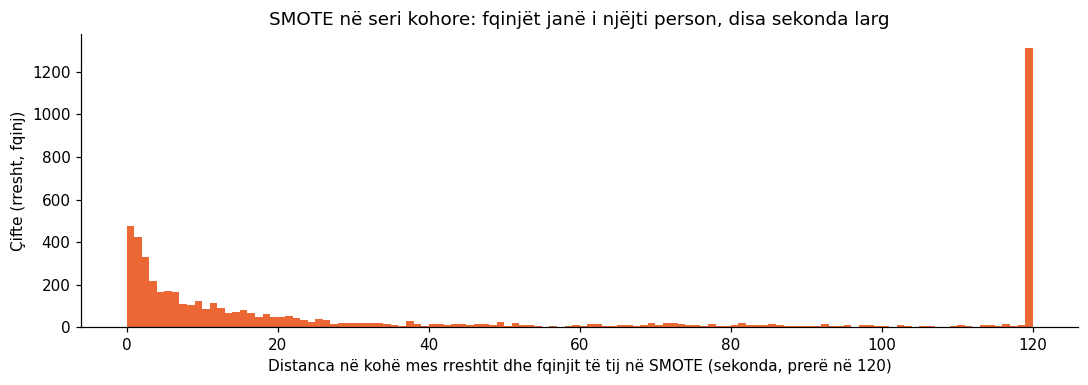

In [17]:
t_U, s_U = U_df["time(s)"].to_numpy(), U_df["seanca"].to_numpy()
dt_fq = np.abs(t_U[:, None] - t_U[fq])
njejta = s_U[:, None] == s_U[fq]

print(f"Fqinjë nga e njëjta seancë: {njejta.mean():.1%}")
print(f"Mediana e distancës në kohë: {np.median(dt_fq[njejta]):.1f} s  |  ≤ 1 s: {(dt_fq[njejta] <= 1).mean():.1%}")

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.hist(np.clip(dt_fq[njejta], 0, 120), bins=np.arange(0, 121, 1), color=C_UPSET)
ax.set_xlabel("Distanca në kohë mes rreshtit dhe fqinjit të tij në SMOTE (sekonda, prerë në 120)")
ax.set_ylabel("Çifte (rresht, fqinj)")
ax.set_title("SMOTE në seri kohore: fqinjët janë i njëjti person, disa sekonda larg")
plt.tight_layout(); plt.show()

> SMOTE nuk e di që këto janë seri kohore, por **99.6% e fqinjëve që zgjedh janë nga e njëjta seancë**, zakonisht vetëm **disa sekonda deri në pak dhjetëra sekonda larg** (mediana ~16 s). Pra, pikat sintetike janë **"momente të shpikura" të të njëjtit person**, mes dy matjeve reale të tij. Nuk janë "persona të rinj të mërzitur".

### M5. Shpërndarjet: reale kundrejt sintetike

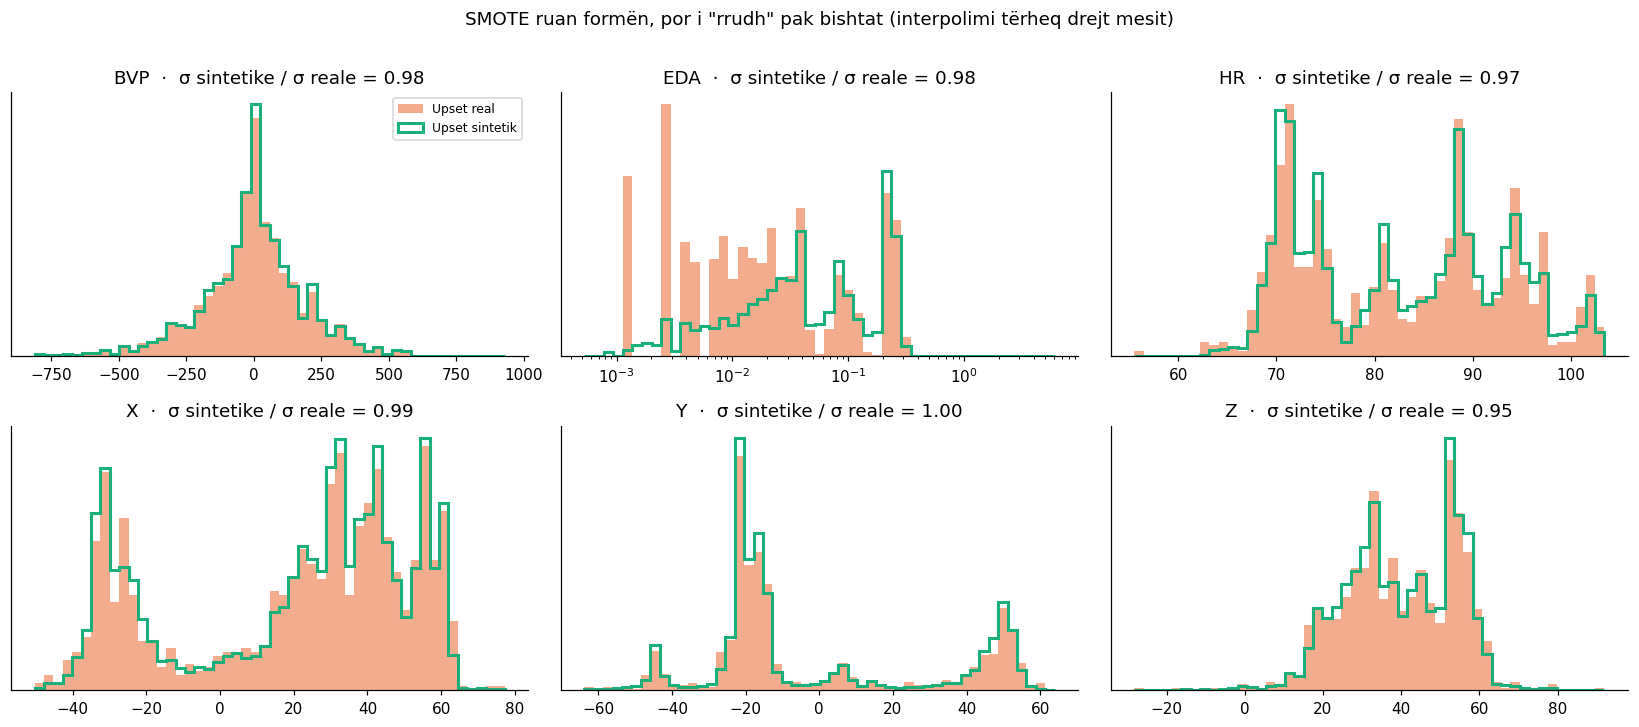

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5))
for a, v in zip(axes.ravel(), VECORI):
    real, sint = U_df[v].to_numpy(), S6_orig[v].to_numpy()
    kufijte = np.histogram_bin_edges(np.r_[real, sint], bins=50)
    if v == "eda":                                   # EDA shtrihet në disa rende madhësie
        poz = np.r_[real, sint]; poz = poz[poz > 0]
        kufijte = np.logspace(np.log10(poz.min()), np.log10(poz.max()), 50); a.set_xscale("log")
    a.hist(real, bins=kufijte, density=True, color=C_UPSET, alpha=0.55, label="Upset real")
    a.hist(sint, bins=kufijte, density=True, histtype="step", lw=2, color=C_SINT, label="Upset sintetik")
    a.set_title(f"{v.upper()}  ·  σ sintetike / σ reale = {sint.std() / real.std():.2f}")
    a.set_yticks([])
axes[0, 0].legend(fontsize=8)
fig.suptitle("SMOTE ruan formën, por i \"rrudh\" pak bishtat (interpolimi tërheq drejt mesit)", y=1.01)
plt.tight_layout(); plt.show()

Raporti **σ sintetike / σ reale** është zakonisht pak më i vogël se 1. Pika e re gjithmonë ndodhet *mes* dy pikave reale, kurrë jashtë tyre. Prandaj SMOTE **nuk krijon kurrë vlera më ekstreme** se ato që ekzistojnë.

### M6. A ruhen korrelacionet mes sinjaleve?

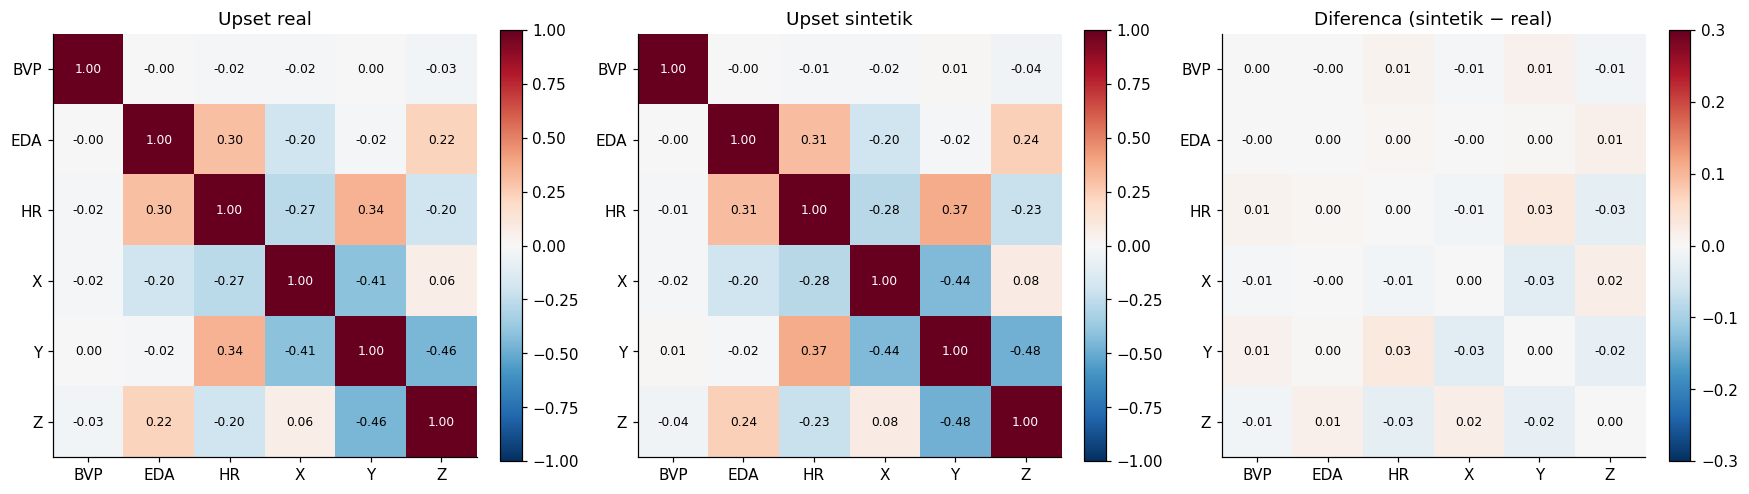

Diferenca maksimale në korrelacion: 0.033


In [19]:
k_real = U_df[VECORI].corr()
k_sint = S6_orig.corr()
etiketat = [v.upper() for v in VECORI]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for a, M, t, vmax in [(axes[0], k_real, "Upset real", 1), (axes[1], k_sint, "Upset sintetik", 1),
                      (axes[2], k_sint - k_real, "Diferenca (sintetik − real)", 0.3)]:
    im = a.imshow(M, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    for (r, c), val in np.ndenumerate(M.to_numpy()):
        a.text(c, r, f"{val:.2f}", ha="center", va="center", fontsize=8,
               color="white" if abs(val) > 0.6 * vmax else "black")
    a.set_xticks(range(6), etiketat); a.set_yticks(range(6), etiketat); a.set_title(t)
    plt.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()
print(f"Diferenca maksimale në korrelacion: {np.abs(k_sint - k_real).to_numpy().max():.3f}")

Korrelacionet ruhen shumë mirë, sepse interpolimi linear mes fqinjëve i respekton lidhjet lokale mes veçorive. Kjo është një nga pikat e forta të SMOTE.

### M7. Sa pika sintetike bien në "territorin e armikut"?

Për çdo pikë, shohim cila klasë është **fqinji i saj më i afërt real** në train. Nëse një pikë Upset sintetike ka si fqinj më të afërt një rresht Normal ose Stressed, ajo ndodhet në një zonë që u përket klasave të tjera dhe mund ta ngatërrojë modelin.

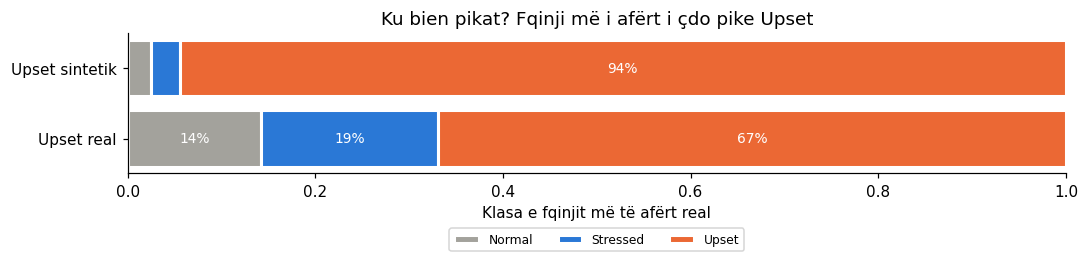

,Normal,Stressed,Upset
Upset real,0.142,0.189,0.669
Upset sintetik,0.025,0.031,0.945


In [20]:
X_trA = sc6.transform(trA[VECORI]); y_trA = trA.LABEL.to_numpy()
nn_all = NearestNeighbors(n_neighbors=2).fit(X_trA)

_, j_real = nn_all.kneighbors(U)                  # fqinji [0] është vetvetja
_, j_sint = nn_all.kneighbors(S6[:10000], n_neighbors=1)

def ndarja(etiketat):
    return pd.Series(etiketat).map(EMRAT).value_counts(normalize=True).reindex(list(EMRAT.values()), fill_value=0)

nd = pd.DataFrame({"Upset real": ndarja(y_trA[j_real[:, 1]]),
                   "Upset sintetik": ndarja(y_trA[j_sint[:, 0]])}).T

fig, ax = plt.subplots(figsize=(10, 2.8))
majtas = np.zeros(len(nd))
for klasa in EMRAT.values():
    ax.barh(nd.index, nd[klasa], left=majtas, color=NGJYRAT[klasa], edgecolor="white", lw=2, label=klasa)
    for y_i, (l, w) in enumerate(zip(majtas, nd[klasa])):
        if w > 0.04:
            ax.text(l + w / 2, y_i, f"{w:.0%}", ha="center", va="center", color="white", fontsize=9)
    majtas += nd[klasa].to_numpy()
ax.set_xlim(0, 1); ax.set_xlabel("Klasa e fqinjit më të afërt real")
ax.set_title("Ku bien pikat? Fqinji më i afërt i çdo pike Upset")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.35), fontsize=8)
plt.tight_layout(); plt.show()
nd.round(3)

> **Rezultati i kundërt nga sa pritej:** pikat sintetike janë **më "të pastra" se ato reale**. Rreth 1 në 3 pika reale Upset ka si fqinj më të afërt një rresht Normal ose Stressed. Te pikat sintetike, kjo ndodh vetëm për ~5%.
>
> Arsyeja: çdo pikë sintetike lind *mes dy pikave Upset*, pra në zemër të zonave Upset. Zonat e përziera, ku Upset takohet me klasat e tjera, mbeten të nënpërfaqësuara. Kështu SMOTE i jep modelit **një pamje më të thjeshtë të klasës Upset se ç'është në realitet**. Pikërisht pikat e kufirit janë ato që synon ta forcojë varianti **Borderline-SMOTE**.

### M8. Si e ndryshon SMOTE kufirin e vendimit?

Trajnojmë një model të thjeshtë (**k-NN, k = 25**) vetëm me EDA dhe HR, për Upset kundrejt të tjerave. Ngjyra tregon probabilitetin që modeli jep për Upset në çdo pikë të planit, dhe vija e zezë është kufiri 0.5.

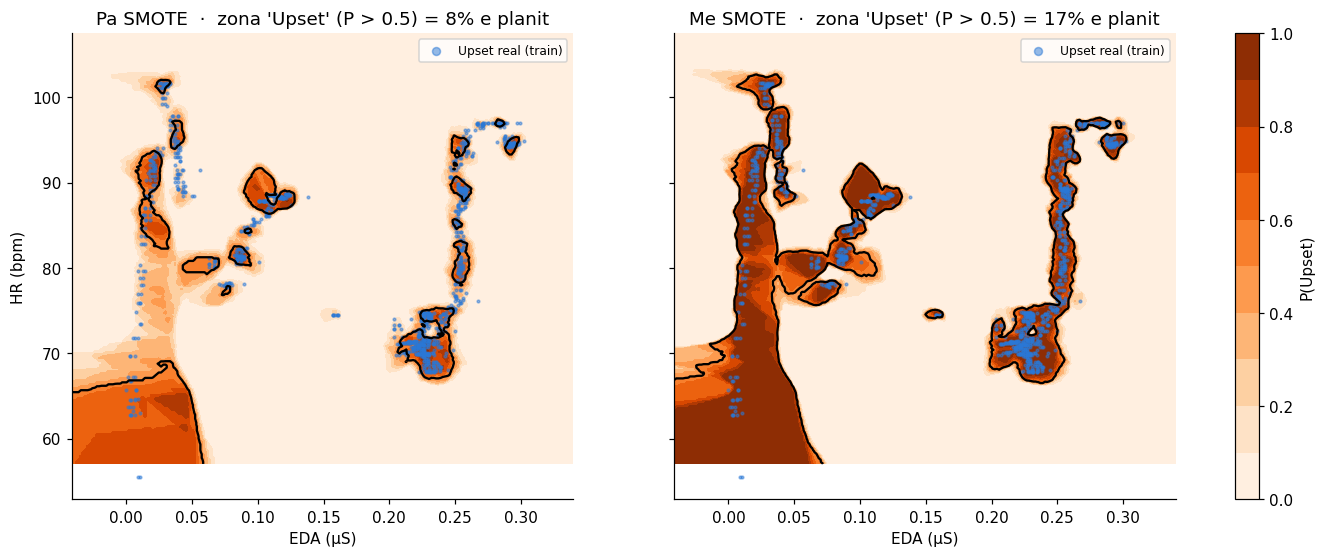

In [21]:
from sklearn.neighbors import KNeighborsClassifier

X2_tr = sc2.transform(W[D2]); yb_tr = (W.LABEL == 2).astype(int).to_numpy()
n_shtese = (W.LABEL == 1).sum() - yb_tr.sum()
S2_std = smote(U2, n_shtese, k=K, random_state=RS)
X2_sm = np.vstack([X2_tr, S2_std]); yb_sm = np.r_[yb_tr, np.ones(n_shtese, int)]

gx, gy = np.meshgrid(np.linspace(*LIM_X, 220), np.linspace(*LIM_Y, 220))
rrjeta = sc2.transform(pd.DataFrame({"eda": gx.ravel(), "hr": gy.ravel()}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for a, (Xt, yt), t in [(axes[0], (X2_tr, yb_tr), "Pa SMOTE"), (axes[1], (X2_sm, yb_sm), "Me SMOTE")]:
    prob = KNeighborsClassifier(n_neighbors=25).fit(Xt, yt).predict_proba(rrjeta)[:, 1].reshape(gx.shape)
    im = a.contourf(gx, gy, prob, levels=np.linspace(0, 1, 11), cmap="Oranges")
    a.contour(gx, gy, prob, levels=[0.5], colors="k", linewidths=1.5)
    a.scatter(*U2_orig.T, s=3, c=C_STRESS, alpha=0.5, label="Upset real (train)")
    a.set_title(f"{t}  ·  zona 'Upset' (P > 0.5) = {(prob > 0.5).mean():.0%} e planit")
    a.set_xlabel("EDA (μS)"); a.legend(loc="upper right", markerscale=3, fontsize=8)
axes[0].set_ylabel("HR (bpm)")
fig.colorbar(im, ax=axes, fraction=0.025, label="P(Upset)")
plt.show()

Pa SMOTE, modeli e jep "Upset" vetëm aty ku pikat Upset janë shumë të dendura, sepse në pjesën tjetër i mbysin klasat e tjera. Me SMOTE, **zona Upset zgjerohet** dhe mbulon të gjitha rrugët e rreshtave reale. Prandaj recall rritet. Por zona e zgjeruar mbulon edhe hapësirë ku jetojnë Normal dhe Stressed, dhe kjo shpjegon pse **precision bie**.

---
## 3. Rasti B: pse rezultati i rastit A është iluzion

Sinjalet maten çdo **0.25 sekonda**, prandaj dy rreshta njëri pas tjetrit janë pothuajse identikë. Me ndarjen rastësore, për shumë rreshta në test ka një "binjak" në train, që është **i njëjti person, një çerek sekonde më herët ose më vonë**.

Le ta matim: për çdo rresht të testit, kush është fqinji më i afërt në train?

Të gjitha   : fqinji më i afërt në train është nga e njëjta seancë në 93.4% të rasteve, dhe ≤ 2 sekonda larg në 54.5%
Vetëm Upset : fqinji më i afërt në train është nga e njëjta seancë në 78.7% të rasteve, dhe ≤ 2 sekonda larg në 27.1%


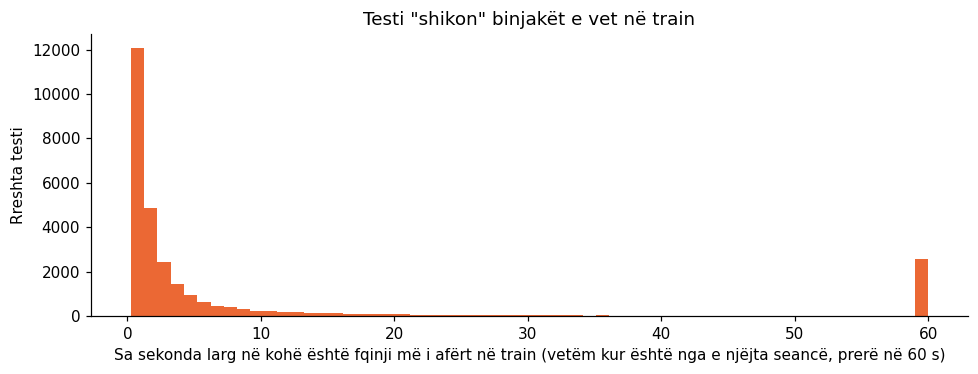

In [22]:
tr, te = bio.loc[~maska_A], bio.loc[maska_A]
sc = StandardScaler().fit(tr[VECORI])
nn = NearestNeighbors(n_neighbors=1).fit(sc.transform(tr[VECORI]))
_, j = nn.kneighbors(sc.transform(te[VECORI]))
fqinji = tr.iloc[j[:, 0]]

njejta_seance = fqinji.seanca.to_numpy() == te.seanca.to_numpy()
dt = np.abs(fqinji["time(s)"].to_numpy() - te["time(s)"].to_numpy())

for emri, m in [("Të gjitha", np.ones(len(te), bool)), ("Vetëm Upset", te.LABEL.to_numpy() == 2)]:
    print(f"{emri:12s}: fqinji më i afërt në train është nga e njëjta seancë në {njejta_seance[m].mean():.1%} "
          f"të rasteve, dhe ≤ 2 sekonda larg në {(njejta_seance & (dt <= 2))[m].mean():.1%}")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(np.clip(dt[njejta_seance], 0, 60), bins=60, color=C_UPSET)
ax.set_xlabel("Sa sekonda larg në kohë është fqinji më i afërt në train (vetëm kur është nga e njëjta seancë, prerë në 60 s)")
ax.set_ylabel("Rreshta testi"); ax.set_title("Testi \"shikon\" binjakët e vet në train")
plt.tight_layout(); plt.show()

> Për **~93%** të rreshtave të testit, fqinji më i afërt në train është nga **e njëjta seancë**, dhe për rreth gjysmën prej tyre është **jo më shumë se 2 sekonda larg**. Histogrami e tregon qartë: shumica e "fqinjëve" janë vetëm pak sekonda larg në kohë. Edhe për klasën Upset, ~79% e fqinjëve janë nga e njëjta seancë. Modeli nuk ka mësuar *"si duket mërzia"*. Ka mësuar *"si duken sinjalet e personit të seancës 16 në ato 6 minuta"*.
>
> SMOTE e përforcon këtë kujtesë, sepse krijon edhe më shumë pika mes rreshtave pothuajse identikë të të njëjtit person.

---
## 4. Rasti C: testi i ndershëm, një seancë e re

Tani simulojmë situatën reale: **një regjistrim i ri** që modeli nuk e ka parë kurrë. E vendosim të gjithë seancën 16 në test. Në train mbeten vetëm **56 rreshta Upset** (seancat 18 dhe 19).

> **Shënim:** dataset-i nuk ka identifikues për pjesëmarrësit, prandaj seancat i kemi rindërtuar nga kolona e kohës. Një seancë është një regjistrim i vazhdueshëm me byzylykun, pra i një personi të vetëm. Por i njëjti person **mund të ketë edhe seanca të tjera** (p.sh. seancën me psikologun dhe seancën e provimit). Kështu që "seancë e re" nuk do të thotë domosdoshmërisht "person që modeli nuk e ka parë kurrë". Kjo e bën testin pak *më të lehtë* se një test me person krejt të ri, dhe megjithatë recall-i del 0.

In [23]:
maska_C = (bio.seanca == 16).to_numpy()

rC_pa = eksperiment(maska_C, "asgje")
rC_me = eksperiment(maska_C, "smote")
rezultatet += [metrikat(rC_pa, "C) Seancë e re", "Pa SMOTE"), metrikat(rC_me, "C) Seancë e re", "SMOTE")]
pd.DataFrame(rezultatet).round(3)

,Rasti,Strategjia,Upset në test,Recall (Upset),Precision (Upset),Macro F1,Balanced Acc.
0,A) Rastësore,Pa SMOTE,479,0.827,0.966,0.939,0.918
1,A) Rastësore,SMOTE,479,0.946,0.802,0.931,0.956
2,C) Seancë e re,Pa SMOTE,1541,0.000,0.000,0.063,0.361
3,C) Seancë e re,SMOTE,1541,0.000,0.000,0.063,0.361


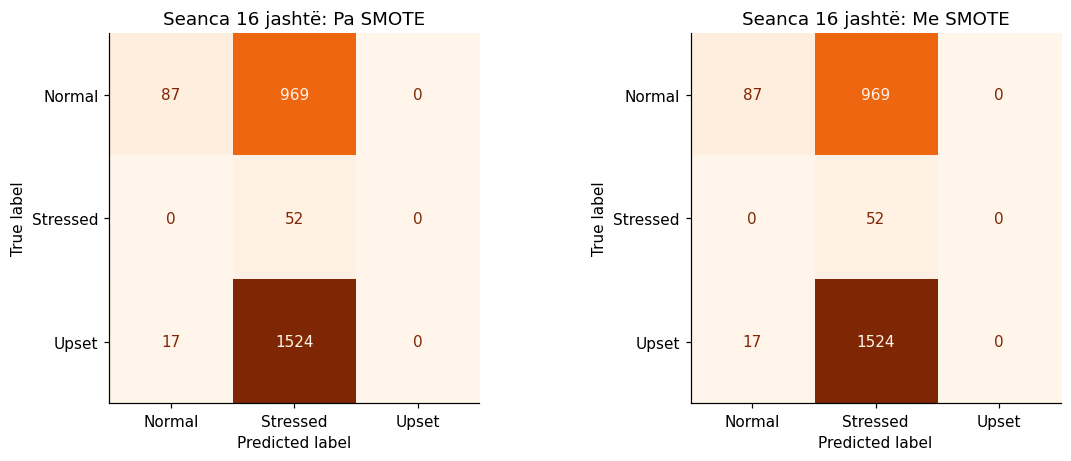

In [24]:
matricat(rC_pa, rC_me, "Seanca 16 jashtë")

**Recall për Upset bie në 0, me SMOTE ose pa SMOTE.** Arsyen e tregon grafiku më poshtë: ku i vendosi SMOTE pikat sintetike dhe ku ndodhen pikat Upset të seancës së re.

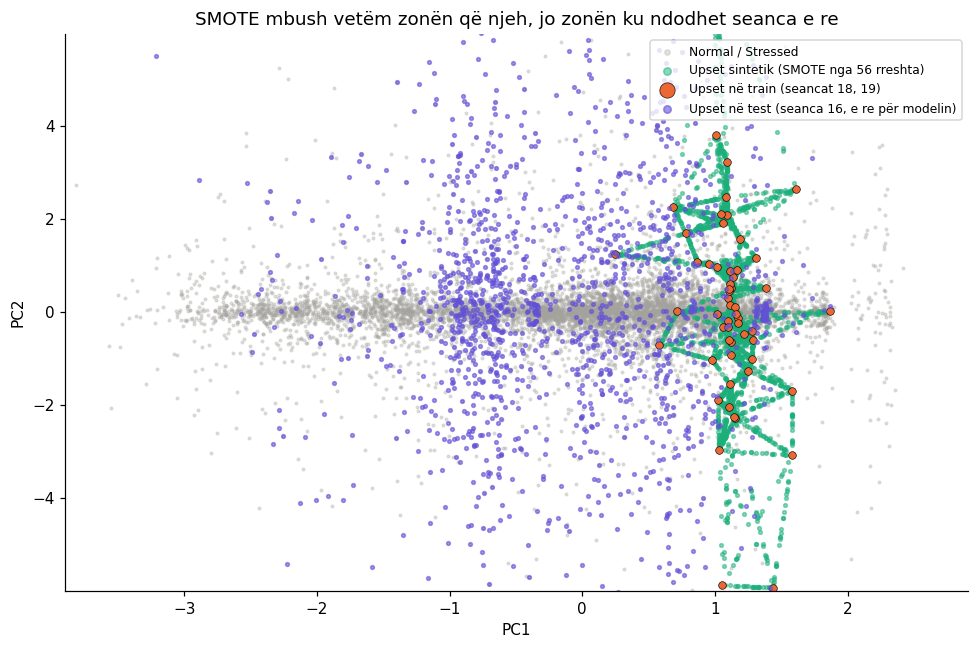

In [25]:
sc = rC_me["scaler"]
X_all = sc.transform(bio[VECORI].to_numpy())
pca = PCA(n_components=2).fit(X_all)

P_sfond = pca.transform(X_all[sfond])
P_sint = pca.transform(rC_me["X_shtese"][:4000])
P_upset_train = pca.transform(X_all[(bio.LABEL == 2).to_numpy() & ~maska_C])
P_upset_test = pca.transform(X_all[(bio.LABEL == 2).to_numpy() & maska_C])

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(*P_sfond.T, s=3, c=GRI, alpha=0.3, label="Normal / Stressed")
ax.scatter(*P_sint.T, s=6, c=C_SINT, alpha=0.5, label="Upset sintetik (SMOTE nga 56 rreshta)")
ax.scatter(*P_upset_train.T, s=25, c=C_UPSET, edgecolors="k", lw=0.4, label="Upset në train (seancat 18, 19)")
ax.scatter(*P_upset_test.T, s=6, c=C_TEST, alpha=0.6, label="Upset në test (seanca 16, e re për modelin)")
ax.set_xlim(np.percentile(P_sfond[:, 0], [0.5, 99.5]) * 1.3)
ax.set_ylim(np.percentile(P_sfond[:, 1], [0.5, 99.5]) * 1.3)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title("SMOTE mbush vetëm zonën që njeh, jo zonën ku ndodhet seanca e re")
ax.legend(loc="upper right", markerscale=2, fontsize=8)
plt.tight_layout(); plt.show()

> SMOTE interpolon **vetëm mes pikave që ekzistojnë**. Kur pakica vjen nga një ose dy seanca, pikat sintetike janë thjesht variacione të atyre seancave. SMOTE nuk mund ta krijojë "mërzinë e dikujt tjetër".

---
## 5. Rasti D: ndarje kronologjike brenda çdo seance

Një kompromis i arsyeshëm: nga çdo seancë, **70% e parë** e kohës shkon në train dhe **30% e fundit** në test. Kështu modeli nuk sheh rreshta "binjakë" nga e njëjta periudhë, por klasa Upset mbetet e pranishme si në train ashtu edhe në test.

In [26]:
pozicioni = bio.groupby("seanca").cumcount() / bio.groupby("seanca")["seanca"].transform("size")
maska_D = (pozicioni >= 0.7).to_numpy()
print("Upset në train:", int(((bio.LABEL == 2) & ~maska_D).sum()), "| Upset në test:", int(((bio.LABEL == 2) & maska_D).sum()))

rD_pa = eksperiment(maska_D, "asgje")
rD_me = eksperiment(maska_D, "smote")
rezultatet += [metrikat(rD_pa, "D) Kronologjike", "Pa SMOTE"), metrikat(rD_me, "D) Kronologjike", "SMOTE")]
pd.DataFrame(rezultatet).round(3)

Upset në train: 877 | Upset në test: 720


,Rasti,Strategjia,Upset në test,Recall (Upset),Precision (Upset),Macro F1,Balanced Acc.
0,A) Rastësore,Pa SMOTE,479,0.827,0.966,0.939,0.918
1,A) Rastësore,SMOTE,479,0.946,0.802,0.931,0.956
2,C) Seancë e re,Pa SMOTE,1541,0.000,0.000,0.063,0.361
3,C) Seancë e re,SMOTE,1541,0.000,0.000,0.063,0.361
4,D) Kronologjike,Pa SMOTE,720,0.218,0.480,0.540,0.517
5,D) Kronologjike,SMOTE,720,0.289,0.175,0.498,0.521


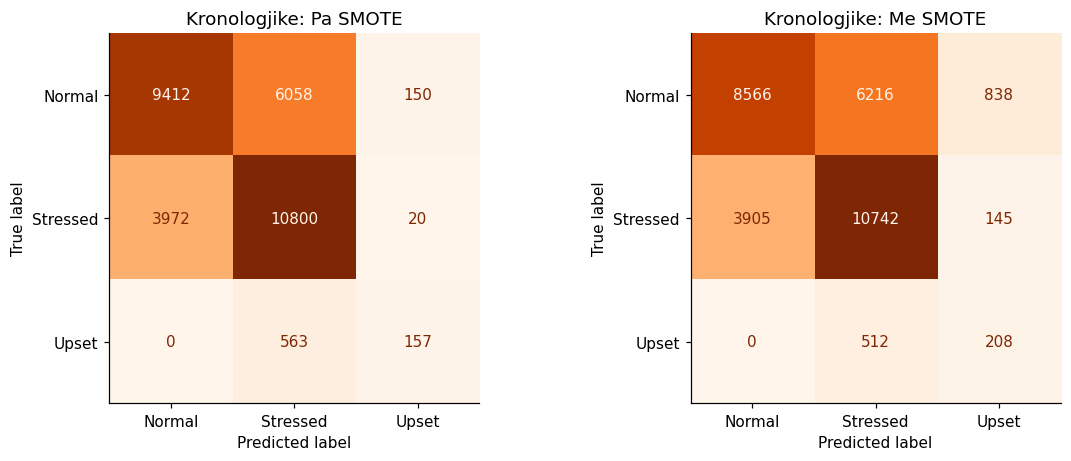

In [27]:
matricat(rD_pa, rD_me, "Kronologjike")

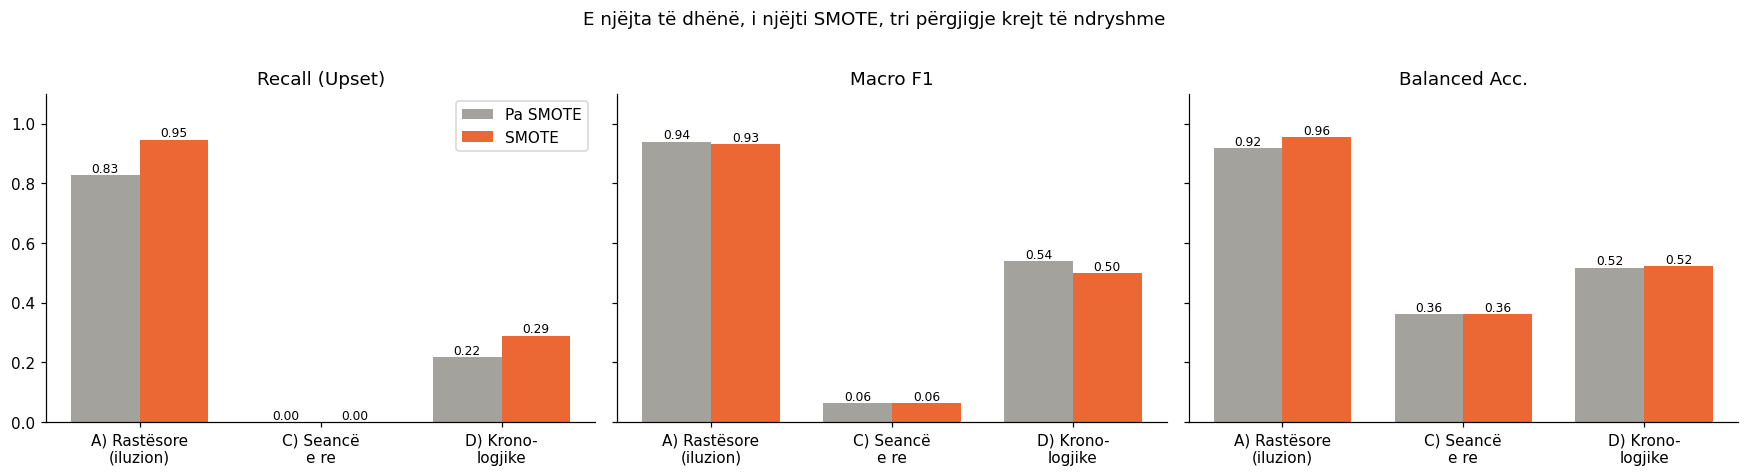

In [28]:
tab = pd.DataFrame(rezultatet)
rastet = tab.Rasti.unique()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for a, metrika in zip(axes, ["Recall (Upset)", "Macro F1", "Balanced Acc."]):
    x = np.arange(len(rastet)); w = 0.38
    for i, (strat, ngj) in enumerate([("Pa SMOTE", GRI), ("SMOTE", C_UPSET)]):
        v = tab[tab.Strategjia == strat].set_index("Rasti").loc[rastet, metrika].to_numpy()
        b = a.bar(x + (i - 0.5) * w, v, w, color=ngj, label=strat)
        a.bar_label(b, fmt="%.2f", fontsize=8)
    a.set_xticks(x, ["A) Rastësore\n(iluzion)", "C) Seancë\ne re", "D) Krono-\nlogjike"])
    a.set_title(metrika); a.set_ylim(0, 1.1)
axes[0].legend()
fig.suptitle("E njëjta të dhënë, i njëjti SMOTE, tri përgjigje krejt të ndryshme", y=1.02)
plt.tight_layout(); plt.show()

> **Te ndarja kronologjike, SMOTE ka një çmim të fshehur.** Recall për Upset rritet pak (0.22 → 0.29), por **precision bie nga 0.48 në 0.18**. Modeli tani e shpall "Upset" shumë më shpesh dhe shumicën e herëve gabon. Si rezultat, **Macro F1 bie** (0.54 → 0.50) dhe Balanced Accuracy mbetet pothuajse e njëjtë.
>
> Pra, në një vlerësim të ndershëm, SMOTE nuk e përmirëson modelin në tërësi. Vetëm e zhvendos atë drejt alarmeve më të shpeshta.
>
> Pragu 70% / 30% është një zgjedhje e vetme. Në Pjesën 7 e kontrollojmë nëse ky përfundim mbetet i njëjtë me pragje të tjera.

---
## 6. Rasti E: SMOTE kundrejt alternativave

A është SMOTE vërtet më i mirë se Random Oversampling (kopjim i thjeshtë) ose `class_weight`? Këtë e testojmë në dy ndarje:
- **A (rastësore)**, ku të gjitha strategjitë do të duken mirë,
- **D (kronologjike)**, që është më afër realitetit.

In [29]:
krahasimi = []
for rasti, maska in [("A) Rastësore", maska_A), ("D) Kronologjike", maska_D)]:
    for strat, emri in [("asgje", "Asgjë"), ("ros", "Random Oversampling"),
                        ("smote", "SMOTE"), ("cw", "class_weight")]:
        krahasimi.append(metrikat(eksperiment(maska, strat), rasti, emri))
krahasimi = pd.DataFrame(krahasimi)
krahasimi.round(3)

,Rasti,Strategjia,Upset në test,Recall (Upset),Precision (Upset),Macro F1,Balanced Acc.
0,A) Rastësore,Asgjë,479,0.827,0.966,0.939,0.918
1,A) Rastësore,Random Oversampling,479,0.923,0.919,0.948,0.949
2,A) Rastësore,SMOTE,479,0.946,0.802,0.931,0.956
3,A) Rastësore,class_weight,479,0.942,0.890,0.944,0.953
4,D) Kronologjike,Asgjë,720,0.218,0.480,0.540,0.517
5,D) Kronologjike,Random Oversampling,720,0.219,0.214,0.498,0.501
6,D) Kronologjike,SMOTE,720,0.289,0.175,0.498,0.521
7,D) Kronologjike,class_weight,720,0.231,0.210,0.502,0.508


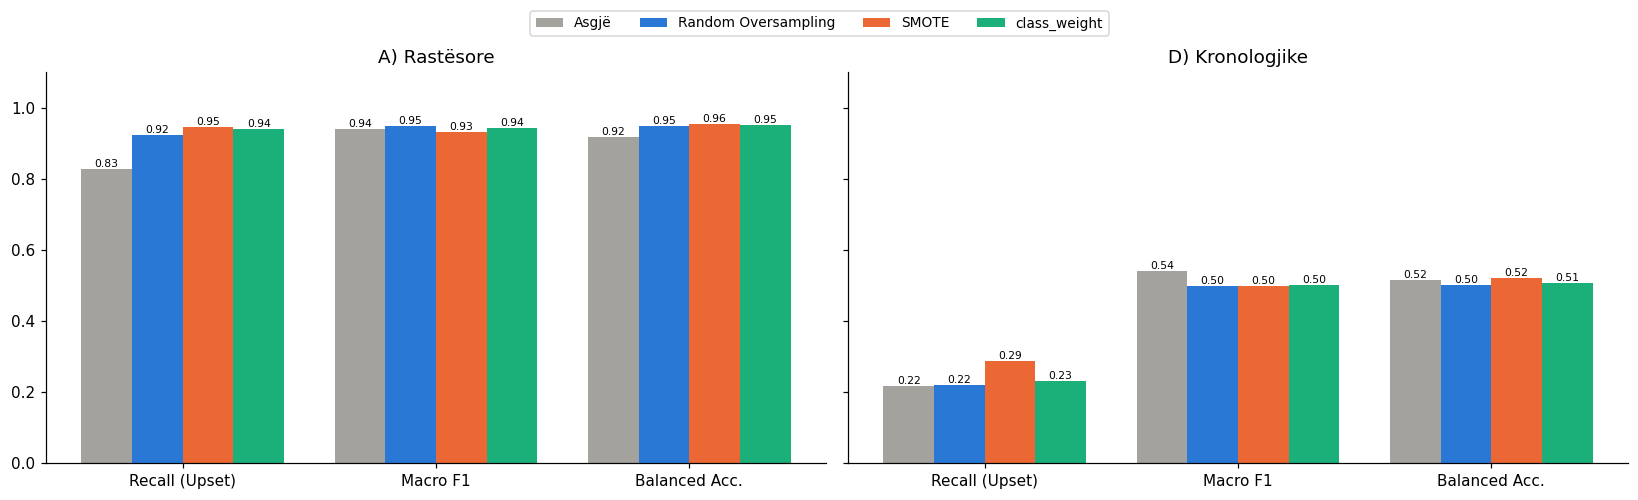

In [30]:
strategjite = ["Asgjë", "Random Oversampling", "SMOTE", "class_weight"]
ngjyrat_s = [GRI, C_STRESS, C_UPSET, C_SINT]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3), sharey=True)
for a, rasti in zip(axes, ["A) Rastësore", "D) Kronologjike"]):
    d = krahasimi[krahasimi.Rasti == rasti].set_index("Strategjia").loc[strategjite]
    x = np.arange(3); w = 0.2
    for i, (s, ngj) in enumerate(zip(strategjite, ngjyrat_s)):
        b = a.bar(x + (i - 1.5) * w, d.loc[s, ["Recall (Upset)", "Macro F1", "Balanced Acc."]], w, color=ngj, label=s)
        a.bar_label(b, fmt="%.2f", fontsize=7)
    a.set_xticks(x, ["Recall (Upset)", "Macro F1", "Balanced Acc."]); a.set_ylim(0, 1.1); a.set_title(rasti)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=4, fontsize=9, bbox_to_anchor=(0.5, 1.06))
plt.tight_layout(); plt.show()

> **Si ta lexosh:**
> - **Ndarja rastësore:** të tria strategjitë duken pothuajse njësoj të mira (recall 0.92–0.95). Edhe kopjimi i thjeshtë (Random Oversampling) "funksionon", sepse rreshtat e testit janë binjakë të rreshtave të train-it. Kur gjithçka funksionon njësoj mirë, kjo është shenjë se testi është shumë i lehtë.
> - **Ndarja kronologjike:** asnjë strategji nuk e mund modelin bazë në Macro F1. SMOTE jep recall-in më të lartë, por edhe precision-in më të ulët.
>
> Problemi nuk është *se si* e balancojmë klasën Upset. Problemi është se klasa Upset vjen nga **1–3 seanca**, dhe asnjë strategji balancimi nuk e zgjidh këtë.

### Efekti i k (numrit të fqinjëve) në ndarjen kronologjike

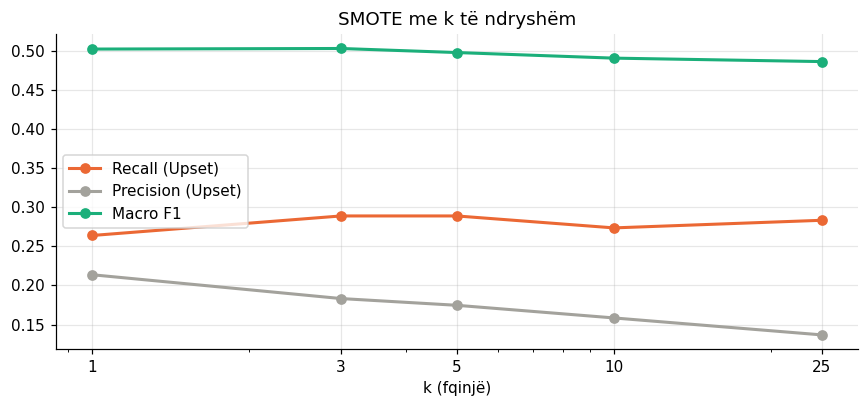

,k,Recall (Upset),Precision (Upset),Macro F1
0,1,0.264,0.214,0.502
1,3,0.289,0.183,0.503
2,5,0.289,0.175,0.498
3,10,0.274,0.158,0.491
4,25,0.283,0.137,0.486


In [31]:
rreshta = []
for k in [1, 3, 5, 10, 25]:
    r = eksperiment(maska_D, "smote", k=k)
    rreshta.append({"k": k, **{m: v for m, v in metrikat(r, "", "").items()
                               if m in ["Recall (Upset)", "Precision (Upset)", "Macro F1"]}})
efekti_k = pd.DataFrame(rreshta)

fig, ax = plt.subplots(figsize=(8, 3.8))
for m, ngj in [("Recall (Upset)", C_UPSET), ("Precision (Upset)", GRI), ("Macro F1", C_SINT)]:
    ax.plot(efekti_k.k, efekti_k[m], "o-", c=ngj, lw=2, label=m)
ax.set_xscale("log"); ax.set_xticks(efekti_k.k, efekti_k.k)
ax.set_xlabel("k (fqinjë)"); ax.set_title("SMOTE me k të ndryshëm"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
efekti_k.round(3)

`k = 1` do të thotë që pikat sintetike krijohen vetëm drejt fqinjit më të afërt, pra shumë afër origjinalit (pothuajse si kopjim). Me `k` më të madh, pikat shtrihen më larg dhe janë më të larmishme, por rritet edhe rreziku që të bien në zonën e klasave të tjera.

---
## 7. Sa të qëndrueshme janë rezultatet?

Të gjitha rezultatet deri tani vijnë nga **një ndarje e vetme** train/test. Ndoshta ndonjë diferencë (p.sh. 0.22 → 0.29) është thjesht rastësi. Prandaj e përsërisim çdo rast disa herë:

| Rasti | Si e përsërisim |
|---|---|
| **A. Rastësore** | 5 ndarje rastësore të ndryshme (`random_state` = 0…4) |
| **C. Seancë e re** | Lëmë jashtë, me radhë, **secilën seancë që ka Upset**: 16 (1 541 rreshta) dhe 18 (53 rreshta). Seanca 19 ka vetëm 3 rreshta Upset, shumë pak për ta testuar. |
| **D. Kronologjike** | 5 pragje të ndryshme: 60%, 65%, 70%, 75% dhe 80% e çdo seance në train |

Çdo përsëritje bëhet dy herë, pa SMOTE dhe me SMOTE. Kështu i krahasojmë **në çifte**, në të njëjtën ndarje. Ky hap zgjat 1–2 minuta.

In [32]:
perseritjet = []

for s in range(5):                                        # A: 5 ndarje rastësore
    _, idx_te = train_test_split(bio.index, test_size=0.3, stratify=bio.LABEL, random_state=s)
    maska = bio.index.isin(idx_te)
    for strat, emri in [("asgje", "Pa SMOTE"), ("smote", "SMOTE")]:
        perseritjet.append({**metrikat(eksperiment(maska, strat), "A) Rastësore", emri), "Varianti": f"seed {s}"})

for seanca in [16, 18]:                                   # C: secila seancë me Upset jashtë
    maska = (bio.seanca == seanca).to_numpy()
    for strat, emri in [("asgje", "Pa SMOTE"), ("smote", "SMOTE")]:
        perseritjet.append({**metrikat(eksperiment(maska, strat), "C) Seancë e re", emri), "Varianti": f"seanca {seanca}"})

for pragu in [0.60, 0.65, 0.70, 0.75, 0.80]:              # D: pragje të ndryshme
    maska = (pozicioni >= pragu).to_numpy()
    for strat, emri in [("asgje", "Pa SMOTE"), ("smote", "SMOTE")]:
        perseritjet.append({**metrikat(eksperiment(maska, strat), "D) Kronologjike", emri), "Varianti": f"{pragu:.0%}"})

perseritjet = pd.DataFrame(perseritjet)
perseritjet.pivot_table(index=["Rasti", "Varianti"], columns="Strategjia",
                        values=["Recall (Upset)", "Precision (Upset)", "Macro F1"], sort=False).round(3)

Recall (Upset)        Precision (Upset)         \
Strategjia                      Pa SMOTE  SMOTE          Pa SMOTE  SMOTE   
Rasti           Varianti                                                   
A) Rastësore    seed 0             0.835  0.948             0.937  0.776   
                seed 1             0.804  0.942             0.941  0.755   
                seed 2             0.858  0.958             0.949  0.768   
                seed 3             0.839  0.952             0.953  0.768   
                seed 4             0.841  0.954             0.926  0.767   
C) Seancë e re  seanca 16          0.000  0.000             0.000  0.000   
                seanca 18          0.000  0.000             0.000  0.000   
D) Kronologjike 60%                0.000  0.001             0.000  0.001   
                65%                0.059  0.128             0.455  0.102   
                70%                0.218  0.289             0.480  0.175   
                75%                0.173  0.198             0.590  0.109   
                80%                0.032  0.034             0.395  0.017   

                          Macro F1         
Strategjia                Pa SMOTE  SMOTE  
Rasti           Varianti                   
A) Rastësore    seed 0       0.936  0.925  
                seed 1       0.930  0.920  
                seed 2       0.942  0.925  
                seed 3       0.938  0.923  
                seed 4       0.935  0.924  
C) Seancë e re  seanca 16    0.063  0.063  
                seanca 18    0.346  0.332  
D) Kronologjike 60%          0.423  0.426  
                65%          0.471  0.466  
                70%          0.540  0.498  
                75%          0.548  0.497  
                80%          0.465  0.438

In [33]:
METRIKAT = ["Recall (Upset)", "Precision (Upset)", "Macro F1", "Balanced Acc."]
permbledhja = perseritjet.groupby(["Rasti", "Strategjia"], sort=False)[METRIKAT].agg(["mean", "std"])
tabela_pm = pd.DataFrame({m: permbledhja[(m, "mean")].map("{:.3f}".format) + " ± "
                             + permbledhja[(m, "std")].fillna(0).map("{:.3f}".format) for m in METRIKAT})
tabela_pm

Recall (Upset) Precision (Upset)       Macro F1  \
Rasti           Strategjia                                                   
A) Rastësore    Pa SMOTE    0.835 ± 0.020     0.941 ± 0.010  0.936 ± 0.004   
                SMOTE       0.951 ± 0.006     0.767 ± 0.007  0.923 ± 0.002   
C) Seancë e re  Pa SMOTE    0.000 ± 0.000     0.000 ± 0.000  0.205 ± 0.200   
                SMOTE       0.000 ± 0.000     0.000 ± 0.000  0.198 ± 0.190   
D) Kronologjike Pa SMOTE    0.096 ± 0.094     0.384 ± 0.226  0.489 ± 0.053   
                SMOTE       0.130 ± 0.118     0.081 ± 0.072  0.465 ± 0.033   

                            Balanced Acc.  
Rasti           Strategjia                 
A) Rastësore    Pa SMOTE    0.920 ± 0.007  
                SMOTE       0.956 ± 0.002  
C) Seancë e re  Pa SMOTE    0.405 ± 0.063  
                SMOTE       0.394 ± 0.046  
D) Kronologjike Pa SMOTE    0.479 ± 0.039  
                SMOTE       0.475 ± 0.042

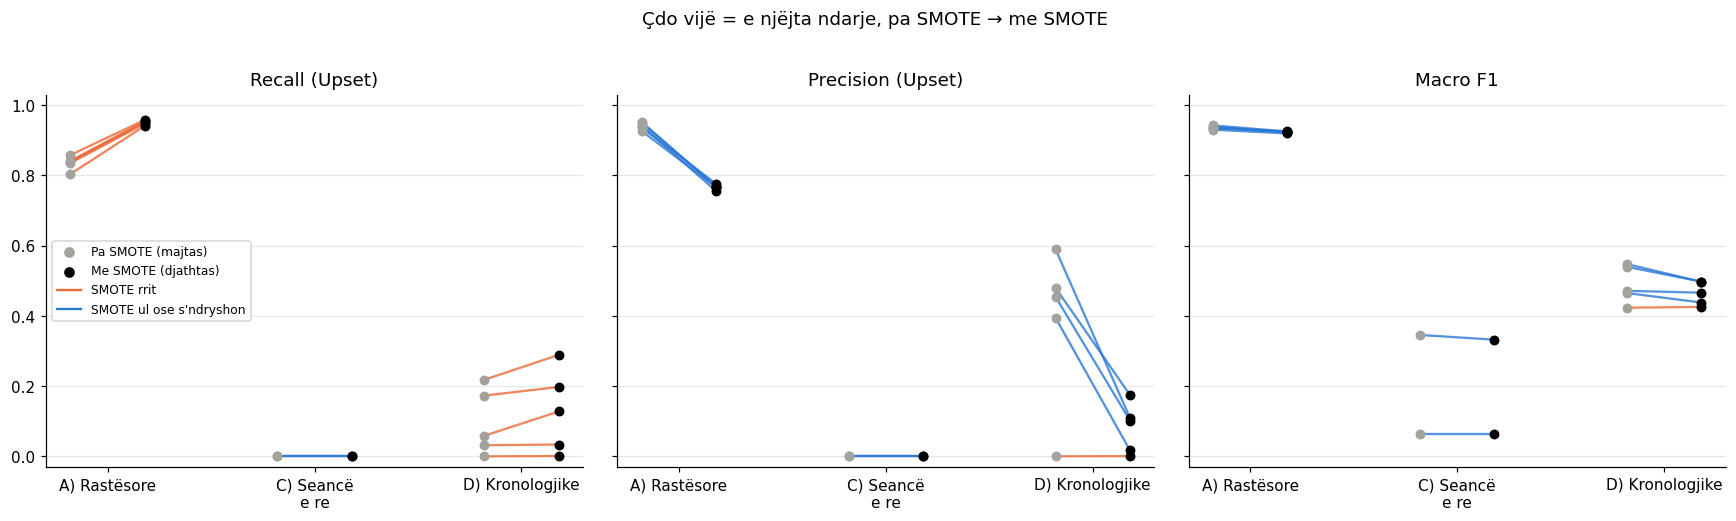

A) Rastësore    : SMOTE e rrit Macro F1 në 0 nga 5 ndarje
C) Seancë e re  : SMOTE e rrit Macro F1 në 0 nga 2 ndarje
D) Kronologjike : SMOTE e rrit Macro F1 në 1 nga 5 ndarje


In [34]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for a, metrika in zip(axes, ["Recall (Upset)", "Precision (Upset)", "Macro F1"]):
    for x0, rasti in enumerate(perseritjet.Rasti.unique()):
        d = perseritjet[perseritjet.Rasti == rasti].pivot(index="Varianti", columns="Strategjia", values=metrika)
        for _, r in d.iterrows():                              # një vijë = një ndarje (çift)
            ngj = C_UPSET if r["SMOTE"] > r["Pa SMOTE"] else C_STRESS
            a.plot([x0 - 0.18, x0 + 0.18], [r["Pa SMOTE"], r["SMOTE"]], "-", c=ngj, lw=1.5, alpha=0.8)
        a.scatter(np.full(len(d), x0 - 0.18), d["Pa SMOTE"], s=30, c=GRI, zorder=3)
        a.scatter(np.full(len(d), x0 + 0.18), d["SMOTE"], s=30, c="k", zorder=3)
    a.set_xticks(range(3), ["A) Rastësore", "C) Seancë\ne re", "D) Kronologjike"])
    a.set_title(metrika); a.set_ylim(-0.03, 1.03); a.grid(axis="y", alpha=0.3)
axes[0].scatter([], [], c=GRI, label="Pa SMOTE (majtas)"); axes[0].scatter([], [], c="k", label="Me SMOTE (djathtas)")
axes[0].plot([], [], c=C_UPSET, label="SMOTE rrit"); axes[0].plot([], [], c=C_STRESS, label="SMOTE ul ose s'ndryshon")
axes[0].legend(fontsize=8, loc="center left")
fig.suptitle("Çdo vijë = e njëjta ndarje, pa SMOTE → me SMOTE", y=1.02)
plt.tight_layout(); plt.show()

for rasti in perseritjet.Rasti.unique():
    d = perseritjet[perseritjet.Rasti == rasti].pivot(index="Varianti", columns="Strategjia", values="Macro F1")
    print(f"{rasti:16s}: SMOTE e rrit Macro F1 në {(d['SMOTE'] > d['Pa SMOTE']).sum()} nga {len(d)} ndarje")

### Çfarë tregon përsëritja

- **A (rastësore): rezultati është shumë i qëndrueshëm, por mbetet iluzion.** Në të 5 ndarjet, SMOTE e ngre recall-in nga ~0.84 në ~0.95 dhe e ul precision-in nga ~0.94 në ~0.77. Madje edhe këtu, **Macro F1 bie pak me SMOTE në të 5 ndarjet**. Qëndrueshmëria nuk e bën rezultatin të vërtetë, sepse të 5 ndarjet kanë të njëjtin problem me "binjakët" në kohë.
- **C (seancë e re): recall = 0 edhe kur lëmë jashtë seancën 18.** Pra, nuk është rastësi e seancës 16. Modeli nuk njeh Upset në asnjë seancë që nuk e ka parë.
- **D (kronologjike): rezultati varet shumë nga pragu.** Recall-i i Upset lëviz nga **0.00 deri në 0.29** sipas pragut, dhe **pragu 70% që përdorëm në Pjesën 5 doli rasti më i favorshëm për SMOTE**. Precision-i bie qartë me SMOTE në 4 pragje (në pragun 60% modeli nuk gjen pothuajse asnjë Upset, me ose pa SMOTE), dhe Macro F1 bie në 4 nga 5.

> **Mësimi:** një rezultat nga një ndarje e vetme mund të jetë rastësisht shumë i mirë ose shumë i keq. Me përsëritje, përfundimi kryesor del **më i fortë**: në vlerësimet e ndershme, SMOTE nuk e përmirëson modelin në mënyrë të qëndrueshme.

---
## 8. Kufizimet

1. **Seancat janë rindërtuar, jo të dhëna.** Dataset-i nuk ka identifikues për pjesëmarrësit. Seancat i nxorëm nga rifillimet e kolonës `time(s)`. Nuk e dimë se cilat seanca i përkasin të njëjtit person, prandaj "seancë e re" nuk është domosdoshmërisht "person i ri".
2. **Çdo rresht (0.25 s) trajtohet si mostër e pavarur.** Në punët shkencore me sinjale fiziologjike zakonisht nxirren veçori nga dritare kohore (p.sh. mesatarja dhe ndryshueshmëria e EDA për 30–60 s, HRV nga BVP). Ne nuk e bëmë këtë qëllimisht, që fokusi të mbetej te SMOTE. Me veçori të tilla, rezultatet absolute ndoshta do të ishin më të mira, por problemi kryesor (Upset nga 1–3 seanca) do të mbetej.
3. **Përshkrimet e klasave** (Normal, Stressed, Upset) janë marrë nga përshkrimet e dataset-it. Nuk kemi pasur qasje te protokolli i plotë se si janë etiketuar momentet.
4. **Një model i vetëm.** Të gjitha eksperimentet përdorin Random Forest me të njëjtat parametra. Modele të tjera mund të reagojnë ndryshe ndaj SMOTE.
5. **Implementimi i SMOTE** llogarit të gjithë matricën e distancave (n × n). Kjo mjafton për ~1 000 mostra të pakicës, si këtu, por për dataset-e shumë të mëdha do të duhej një kërkim më efikas i fqinjëve (p.sh. KD-tree).

---
## 9. Përfundimet

| Rasti | Çfarë pamë |
|---|---|
| **0. Mekanizmi** | SMOTE krijon pika vetëm në segmentet mes fqinjëve realë. Nuk shpik zona të reja. |
| **1. Eksplorimi** | 96.5% e klasës Upset vjen nga **një seancë e vetme** (~6 minuta). |
| **A. Ndarje rastësore** | Recall 0.83 → 0.95 me SMOTE. Duket sukses. |
| **B. Pse është iluzion** | 93% e rreshtave të testit kanë fqinjin më të afërt në train nga e njëjta seancë, gjysma prej tyre ≤ 2 sekonda larg. |
| **C. Seancë e re** | Recall = **0**, me ose pa SMOTE, si për seancën 16 ashtu edhe për seancën 18. |
| **D. Kronologjike** | Recall 0.22 → 0.29, por precision 0.48 → 0.18 dhe Macro F1 **bie**. |
| **7. Përsëritjet** | Pragu 70% ishte rasti më i favorshëm për SMOTE. Në 12 ndarjet e përsëritura, SMOTE e rrit Macro F1 vetëm **1 herë**. |
| **E. Alternativat** | Te ndarja rastësore të gjitha strategjitë duken shkëlqyeshëm. Te ndarja e ndershme asnjëra nuk e mund modelin bazë. |
| **k** | k më i madh: pika sintetike më të larmishme, por precision bie (0.21 → 0.14). |

### Përgjigjja e pyetjes së titullit

> *A mund ta mësojmë një makinë të njohë një gjendje emocionale që në dataset pothuajse nuk ekziston?*

**Jo vetëm me SMOTE.** SMOTE **balancon numrat, jo informacionin**. "The Missing 1.54%" në fakt është **6 minuta nga një person**. SMOTE mund t'i shumëzojë ato 6 minuta në mijëra rreshta, por nuk mund ta mësojë modelin si duket mërzia te dikush tjetër.

### Tri rregullat
1. SMOTE **vetëm në train**, gjithmonë pas ndarjes.
2. Ndarja train/test duhet të pasqyrojë përdorimin real (persona, seanca, kohë), jo rreshta të rastësishëm.
3. Para SMOTE, pyet: **nga sa burime të pavarura vjen pakica?** Nëse vjen nga 1–2, problemi nuk zgjidhet me më shumë rreshta sintetikë, por me më shumë të dhëna reale.